In [1]:
import numpy as np
import xarray as xr
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d

import glob
import os
import warnings
from collections import defaultdict
from pathlib import Path

#import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import cmocean
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D


from swot_analysis import compute_pass_spectra
from swot_analysis import load_swot_l2_expert 


In [2]:
def build_box_dataset(ds_segments, box_deg=2.0, method='mean',
                      min_sampling_fraction=0.5, var='psd'):
    """Gridded (lat, lon, wavenumber) box average; lat/lon are box centres."""
    if method not in ('mean', 'median', 'log'):
        raise ValueError(f"method must be 'mean', 'median' or 'log', got {method!r}")
    lat = ds_segments['lat_mean'].values
    lon = ds_segments['lon_mean'].values
    lat_idx = np.floor(lat / box_deg).astype(int)
    lon_idx = np.floor(lon / box_deg).astype(int)
    box_to_segs = defaultdict(list)
    for i, key in enumerate(zip(lat_idx, lon_idx)):
        box_to_segs[key].append(i)

    psd_all = ds_segments[var].values
    wavenumber = ds_segments['wavenumber'].values
    li_axis = np.arange(lat_idx.min(), lat_idx.max() + 1)
    lo_axis = np.arange(lon_idx.min(), lon_idx.max() + 1)
    n_max = max(len(v) for v in box_to_segs.values())
    psd_grid = np.full((li_axis.size, lo_axis.size, wavenumber.size), np.nan)
    n_grid = np.zeros((li_axis.size, lo_axis.size), dtype=int)

    for (li, loi), idxs in box_to_segs.items():
        if len(idxs) < min_sampling_fraction * n_max:
            continue
        sub = psd_all[idxs, :]
        if method == 'mean':
            p = np.nanmean(sub, axis=0)
        elif method == 'median':
            p = np.nanmedian(sub, axis=0)
        else:
            with np.errstate(divide='ignore', invalid='ignore'):
                p = np.exp(np.nanmean(np.log(sub), axis=0))
        psd_grid[li - li_axis[0], loi - lo_axis[0]] = p
        n_grid[li - li_axis[0], loi - lo_axis[0]] = len(idxs)

    return xr.Dataset(
        data_vars=dict(
            mean_psd=(['lat', 'lon', 'wavenumber'], psd_grid,
                      {'long_name': 'Box-mean SSH(A) PSD', 'units': 'm^2 / (cycles/km)'}),
            n_segments=(['lat', 'lon'], n_grid),
            sampling_fraction=(['lat', 'lon'], n_grid / n_max),
        ),
        coords=dict(
            lat=('lat', (li_axis + 0.5) * box_deg, {'units': 'degrees_north'}),
            lon=('lon', (lo_axis + 0.5) * box_deg, {'units': 'degrees_east'}),
            wavenumber=('wavenumber', wavenumber, {'units': 'cycles/km'}),
        ),
        attrs=dict(box_size_deg=box_deg, min_sampling_fraction=min_sampling_fraction),
    )
def plot_box(var: np.array, lon: np.array, lat: np.array,
             box_deg: float = None,
             projection: ccrs = ccrs.Robinson(), cmap: str = "viridis",
             figsize: tuple = (14, 7),
             title: str = "Number of observations per box", label: str = "Number of observations",
             vmin: float = None, vmax: float = None,
             fig = None, ax = None
            ):
    mask = np.isfinite(var)
    lon = lon[mask]
    lat = lat[mask]
    var = var[mask]

    # Infer box size from the spacing of box centers if not given
    if box_deg is None:
        lat_diffs = np.diff(np.unique(np.round(lat, 6)))
        lon_diffs = np.diff(np.unique(np.round(lon, 6)))
        box_deg = np.min(np.concatenate([lat_diffs, lon_diffs]))

    # Reconstruct the regular grid of box centers
    lat_centers = np.arange(lat.min(), lat.max() + box_deg, box_deg)
    lon_centers = np.arange(lon.min(), lon.max() + box_deg, box_deg)

    lat_idx = np.round((lat - lat_centers[0]) / box_deg).astype(int)
    lon_idx = np.round((lon - lon_centers[0]) / box_deg).astype(int)

    grid = np.full((lat_centers.size, lon_centers.size), np.nan)
    grid[lat_idx, lon_idx] = var

    # pcolormesh wants cell edges, not centers
    lat_edges = np.concatenate([lat_centers - box_deg / 2, [lat_centers[-1] + box_deg / 2]])
    lon_edges = np.concatenate([lon_centers - box_deg / 2, [lon_centers[-1] + box_deg / 2]])

    if ax is None:
        fig = plt.figure(figsize=figsize)
        ax = plt.axes(projection=projection)
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)

    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.xlabel_style = {"size": 10, "color": "black"}
    gl.ylabel_style = {"size": 10, "color": "black"}

    if norm is not None:
        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), norm=norm)
    else:
        if vmin is None:
            vmin, vmax = np.nanmin(var), np.nanmax(var)

        sc = ax.pcolormesh(lon_edges, lat_edges, grid,
                            cmap=cmap, shading='flat',
                            transform=ccrs.PlateCarree(), vmin=vmin, vmax=vmax)

    cb = plt.colorbar(sc, ax=ax, shrink=0.6,pad=-0.1,orientation='horizontal')
    cb.set_label(label)
    ax.set_title(title)

    return fig, ax
def estimate_separation_scale_adaptative(psd_all,
                                         wavenumber,
                                         log_k_uniform,
                                         dlogk,
                                         search_mask,
                                         low_k_band: tuple,
                                         high_k_band: tuple,
                                         smooth_window: int = 7,
                                         polyorder: int = 2,
                                         search_range: tuple = None,
                                         n_interp: int = 200,
                                         verbose: bool = False) -> xr.Dataset:
    
    p = psd_all
    valid = np.isfinite(p) & (p > 0)
    if valid.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass
    k = wavenumber[valid]
    logp = np.log10(p[valid])
    
    # --- Plateau slopes: simple linear fit on RAW (unsmoothed)
    # points within each band, so no window-straddling bias here ---
    low_mask = (k >= low_k_band[0]) & (k <= low_k_band[1])
    high_mask = (k >= high_k_band[0]) & (k <= high_k_band[1])

    if low_mask.sum() < 3 or high_mask.sum() < 3:
        if verbose:
            print(f"Box {i}: not enough points in plateau bands "
                  f"(low={low_mask.sum()}, high={high_mask.sum()}), skipping.")
        pass

    slope_low = np.polyfit(np.log10(k[low_mask]), logp[low_mask], 1)[0]
    slope_high = np.polyfit(np.log10(k[high_mask]), logp[high_mask], 1)[0]
    #slope_low_all[i] = slope_low
    #slope_high_all[i] = slope_high

    # Adaptive threshold: midpoint between the two plateau slopes
    threshold = 0.5 * (slope_low + slope_high)
    #threshold_used[i] = threshold

    # Expect mesoscale (low-k) STEEPER than sub-mesoscale (high-k),
    # i.e. slope_low < slope_high (more negative = steeper).
    if slope_low >= slope_high:
        if verbose:
            print(f"Box {i}: low-k slope ({slope_low:.2f}) not steeper "
                  f"than high-k slope ({slope_high:.2f}) — no clear "
                  f"mesoscale-to-submesoscale steepening-to-shallowing "
                  f"transition, skipping.")
        pass

    
    # --- Local slope curve via SG, same as before ---
    interp_fn = interp1d(np.log10(k), logp, bounds_error=False, fill_value=np.nan)
    logp_uniform = interp_fn(log_k_uniform)
    valid_u = ~np.isnan(logp_uniform)
    if valid_u.sum() < smooth_window:
        if verbose:
            print('Well well well')
        pass

    
    slope_curve = np.full(n_interp, np.nan)
    win = min(smooth_window, valid_u.sum() if valid_u.sum() % 2 == 1 else valid_u.sum() - 1)
    if win <= polyorder:
        if verbose:
            print('Well well well')
        pass
    slope_curve[valid_u] = savgol_filter(logp_uniform[valid_u], window_length=win,
                                              polyorder=polyorder, deriv=1, delta=dlogk)

    mask = search_mask & valid_u
    idxs = np.where(mask)[0]
    if len(idxs) < 2:
        if verbose:
            print(f"Box {i}: fewer than 2 points in search range, skipping.")
        pass

    diff = slope_curve[idxs] - threshold
    sign_change = np.where(np.diff(np.sign(diff)) != 0)[0]
    if len(sign_change) == 0:
        if verbose:
            print(f"Box {i}: slope never crosses adaptive threshold "
                  f"{threshold:.2f}.")
        pass
    try:
        j = sign_change[0]
        frac = -diff[j] / (diff[j + 1] - diff[j])
        i1, i2 = idxs[j], idxs[j + 1]
        log_k_cross = log_k_uniform[i1] + frac * (log_k_uniform[i2] - log_k_uniform[i1])
        separation_k = 10 ** log_k_cross
    except:
        separation_k = np.nan
    return separation_k, threshold,slope_low, slope_high
    
def wrap_separation_scale_adaptive(ds_box: xr.Dataset,
                                        low_k_band: tuple,
                                        high_k_band: tuple,
                                        smooth_window: int = 7,
                                        polyorder: int = 2,
                                        search_range: tuple = None,
                                        n_interp: int = 200,
                                        verbose: bool = False) -> xr.Dataset:
    """
    Non-parametric separation scale using an adaptive (per-box) slope
    threshold, calibrated to each spectrum's own mesoscale (low-k, steep)
    and sub-mesoscale (high-k, shallower) plateau slopes, instead of a
    fixed universal reference slope like -2.

    Physical convention: mesoscale (low-k) is expected to be steeper
    (more negative slope) than sub-mesoscale (high-k), consistent with
    the transition from geostrophic/QG turbulence (~ -5 to -11/3) to a
    shallower sub-mesoscale regime (~ -2 to -5/3).

    Parameters
    ----------
    low_k_band, high_k_band : tuple(float, float)
        Wavenumber ranges (cycles/km) used to estimate the plateau slope
        on each side of the transition, well away from the break itself.
    smooth_window, polyorder : SG smoothing parameters for the local-slope
        curve used to locate the crossing.
    search_range : tuple(float, float), optional
        Restrict the crossing search to this wavenumber range (defaults
        to the union of low_k_band and high_k_band).
    """
    wavenumber = ds_box['wavenumber'].values
    psd_all    = ds_box['mean_psd'].values
    n_boxes    = psd_all.shape[0]

    k_valid = wavenumber > 0
    wavenumber = wavenumber[k_valid]
    psd_all = psd_all[:, k_valid]
    log_k_orig = np.log10(wavenumber)

    if smooth_window % 2 == 0:
        smooth_window += 1

    log_k_uniform = np.linspace(log_k_orig.min(), log_k_orig.max(), n_interp)
    dlogk = log_k_uniform[1] - log_k_uniform[0]

    if search_range is None:
        k_lo = low_k_band[0]
        k_hi = high_k_band[1]
    else:
        k_lo, k_hi = search_range
    search_mask = (10**log_k_uniform >= k_lo) & (10**log_k_uniform <= k_hi)

    separation_k    = np.full(n_boxes, np.nan)
    slope_low_all   = np.full(n_boxes, np.nan)
    slope_high_all  = np.full(n_boxes, np.nan)
    threshold_used  = np.full(n_boxes, np.nan)

    for i in range(n_boxes):
        sep_k, threshold,slope_low, slope_high = estimate_separation_scale_adaptative(psd_all[i],wavenumber,log_k_uniform,dlogk,
                                                                                      search_mask,
                                                                                      low_k_band, high_k_band,
                                                                                     smooth_window = smooth_window,
                                                                                     polyorder=polyorder,
                                                                                     search_range = search_range,
                                                                                     n_interp=n_interp,
                                                                                     verbose=verbose)
        separation_k[i] = sep_k
        threshold_used[i] = threshold
        slope_low_all[i] = slope_low
        slope_high_all[i] = slope_high

    ds_out = ds_box.copy()
    ds_out['separation_wavenumber'] = (
        ['box'], separation_k,
        {'long_name': 'Wavenumber of adaptive-threshold slope crossing '
                       '(mesoscale-to-submesoscale transition)',
         'units': 'cycles/km'}
    )
    ds_out['separation_wavelength'] = (
        ['box'], 1.0 / separation_k,
        {'long_name': 'Separation scale (1/wavenumber)', 'units': 'km'}
    )
    ds_out['slope_low_k'] = (['box'], slope_low_all,
                              {'long_name': 'Fitted mesoscale (low-k) plateau slope'})
    ds_out['slope_high_k'] = (['box'], slope_high_all,
                               {'long_name': 'Fitted sub-mesoscale (high-k) plateau slope'})
    ds_out['adaptive_threshold'] = (['box'], threshold_used,
                                     {'long_name': 'Midpoint slope threshold used per box'})
    return ds_out

In [14]:
#DATA_DIR = '/work/uo0122/u241387/SWOT_SSH/diags_matched/'
DATA_DIR = '/Volumes/PortableSSD/diags_2024/'
ds_months = xr.open_dataset(DATA_DIR+'matched_spectra_2024_1000km_new.nc')
ds_months_flag = ds_months.where(ds_months.qc_ok,drop=True)

ds250_months = xr.open_dataset(DATA_DIR+'matched_spectra_2024_250km_new.nc')
ds250_months_flag = ds250_months.where(ds250_months.qc_ok,drop=True)

In [6]:
ds_boxes = xr.open_dataset(DATA_DIR+'matched_boxes_2deg_2024_1000km_new.nc')
ds250_boxes = xr.open_dataset(DATA_DIR+'matched_boxes_2deg_2024_250km_new.nc')

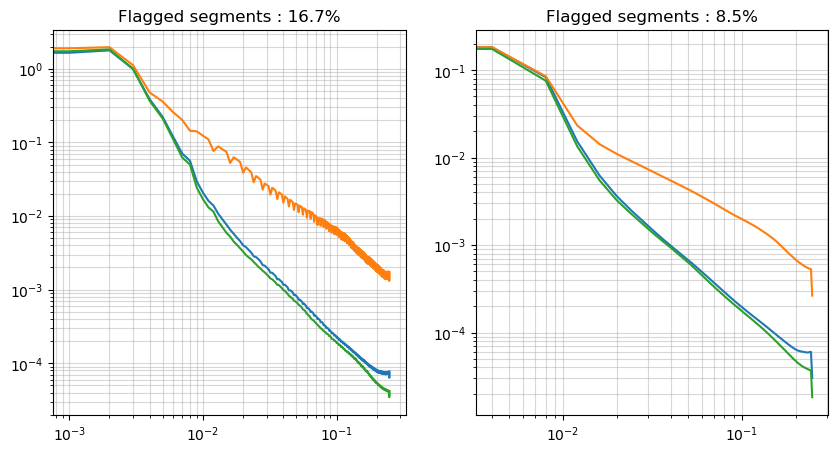

In [15]:
fig, axs = plt.subplots(1,2,figsize=(10,5))
axs[0].loglog(ds_months.wavenumber,ds_months.expert_psd.mean('segment'))
axs[0].loglog(ds_months.wavenumber,ds_months.predicted_psd.mean('segment'))
axs[0].loglog(ds_months_flag.wavenumber,ds_months_flag.predicted_psd.mean('segment'))
axs[0].set_title(f'Flagged segments : {(ds_months.segment.size - ds_months_flag.segment.size)/ds_months.segment.size*100:.1f}%')

axs[1].loglog(ds250_months.wavenumber,ds250_months.expert_psd.mean('segment'))
axs[1].loglog(ds250_months.wavenumber,ds250_months.predicted_psd.mean('segment'))
axs[1].loglog(ds250_months_flag.wavenumber,ds250_months_flag.predicted_psd.mean('segment'))
axs[1].set_title(f'Flagged segments : {(ds250_months.segment.size - ds250_months_flag.segment.size)/ds250_months.segment.size*100:.1f}%')
for ax in axs:
    ax.grid(True,which='both',alpha=0.5)
    

## Flagging tests cells

In [54]:
def _hf_ratio(k, predicted, expert, k_min, k_max):
    """Mean predicted / mean expert PSD for k >= k_min (NaN if undefined)."""
    m = (k >= k_min) & (k<=k_max) & np.isfinite(predicted) & np.isfinite(expert)
    if m.sum() < 3:
        return np.nan
    e = float(np.mean(expert[m]))
    return float(np.mean(predicted[m]) / e) if e > 0 else np.nan

In [55]:
i = 30
_hf_ratio(ds_months.wavenumber, ds_months.sel(segment=i).predicted_psd, ds_months.sel(segment=i).expert_psd, 1/250,1/5)

0.9578328191431497

In [59]:
bad_values = {}
for i in ds250_months.segment[:100]:
    _= _hf_ratio(ds250_months.wavenumber, ds250_months.sel(segment=i).predicted_psd, ds250_months.sel(segment=i).expert_psd, 1/100,1/5)
    if  _ > 1.2:
        bad_values[str(i.values)] = _

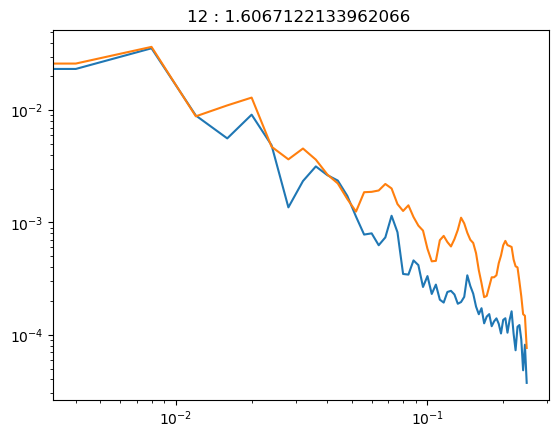

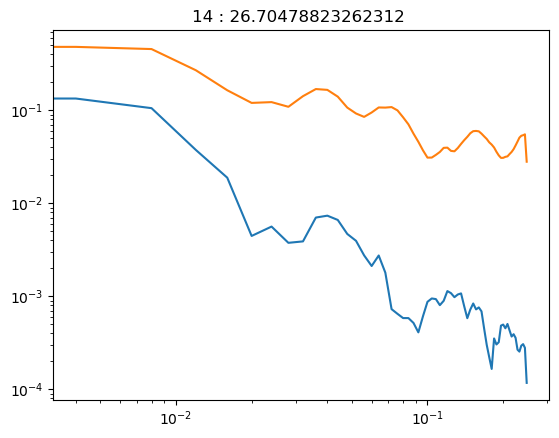

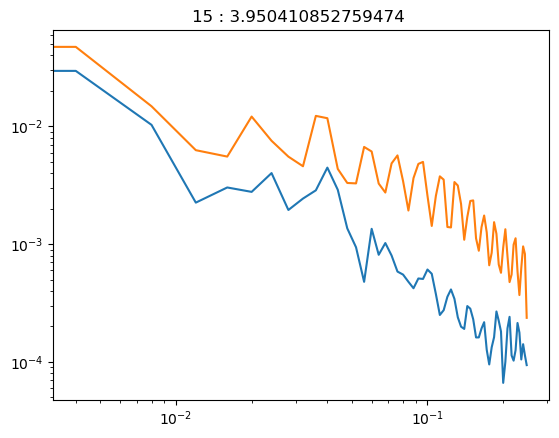

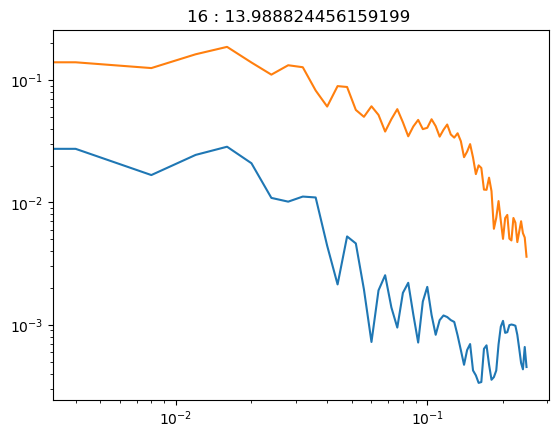

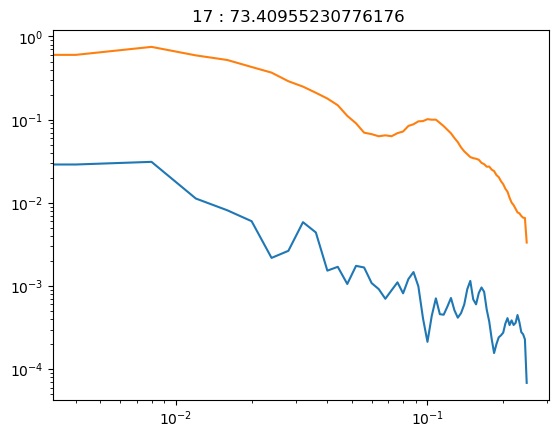

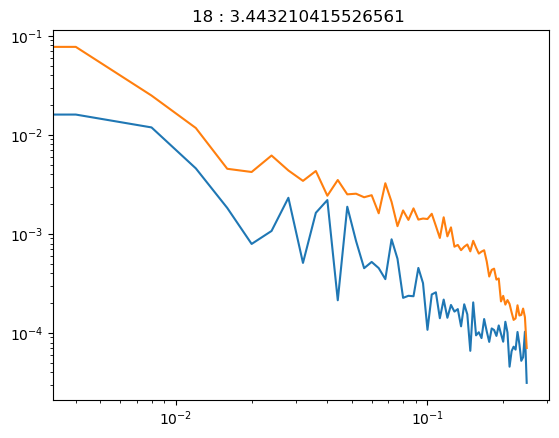

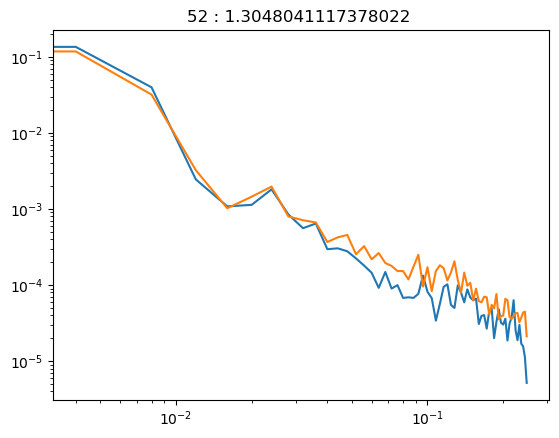

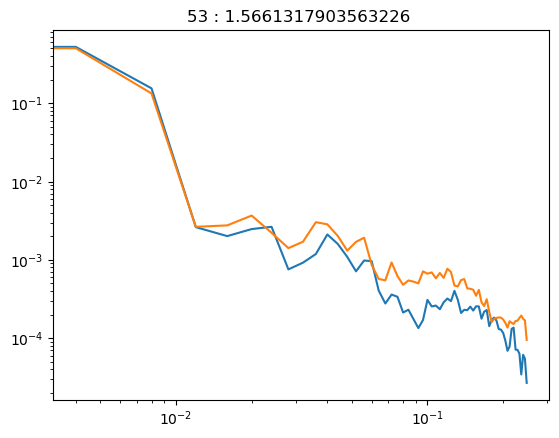

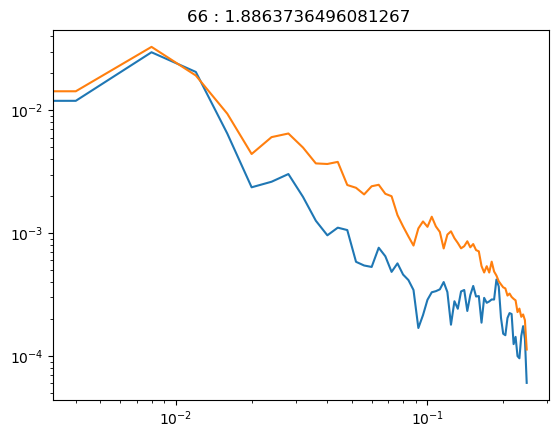

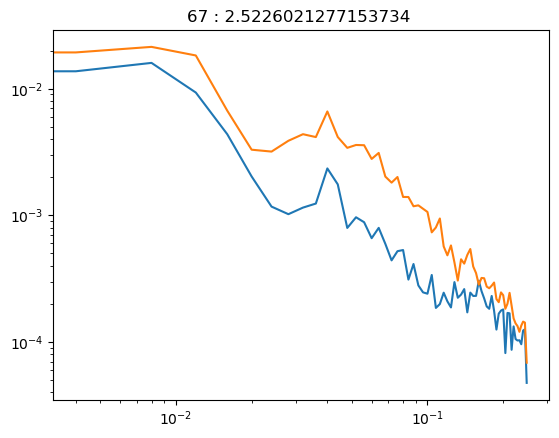

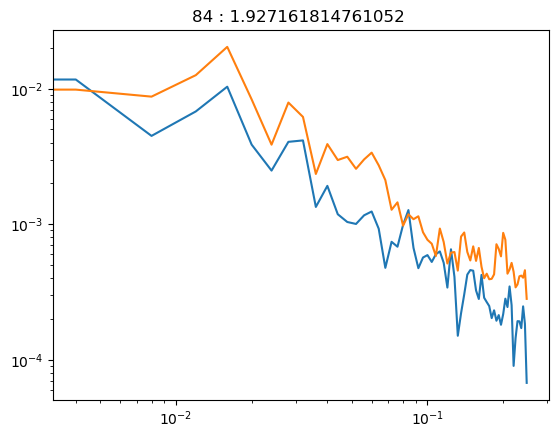

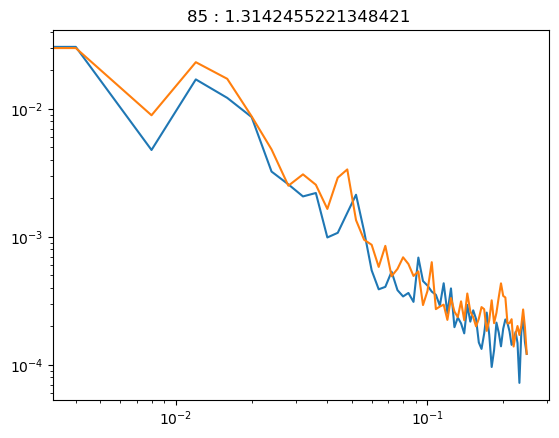

In [63]:
for s in bad_values.keys():
    plt.figure()
    plt.loglog(ds250_months.sel(segment=int(s)).wavenumber,ds250_months.sel(segment=int(s)).expert_psd)
    plt.loglog(ds250_months.sel(segment=int(s)).wavenumber,ds250_months.sel(segment=int(s)).predicted_psd)
    plt.title(s+ f' : {bad_values[s]} ')

In [18]:
ds_boxes_bis = build_box_dataset(ds_months_flag,min_sampling_fraction=0.15,var='predicted_psd')

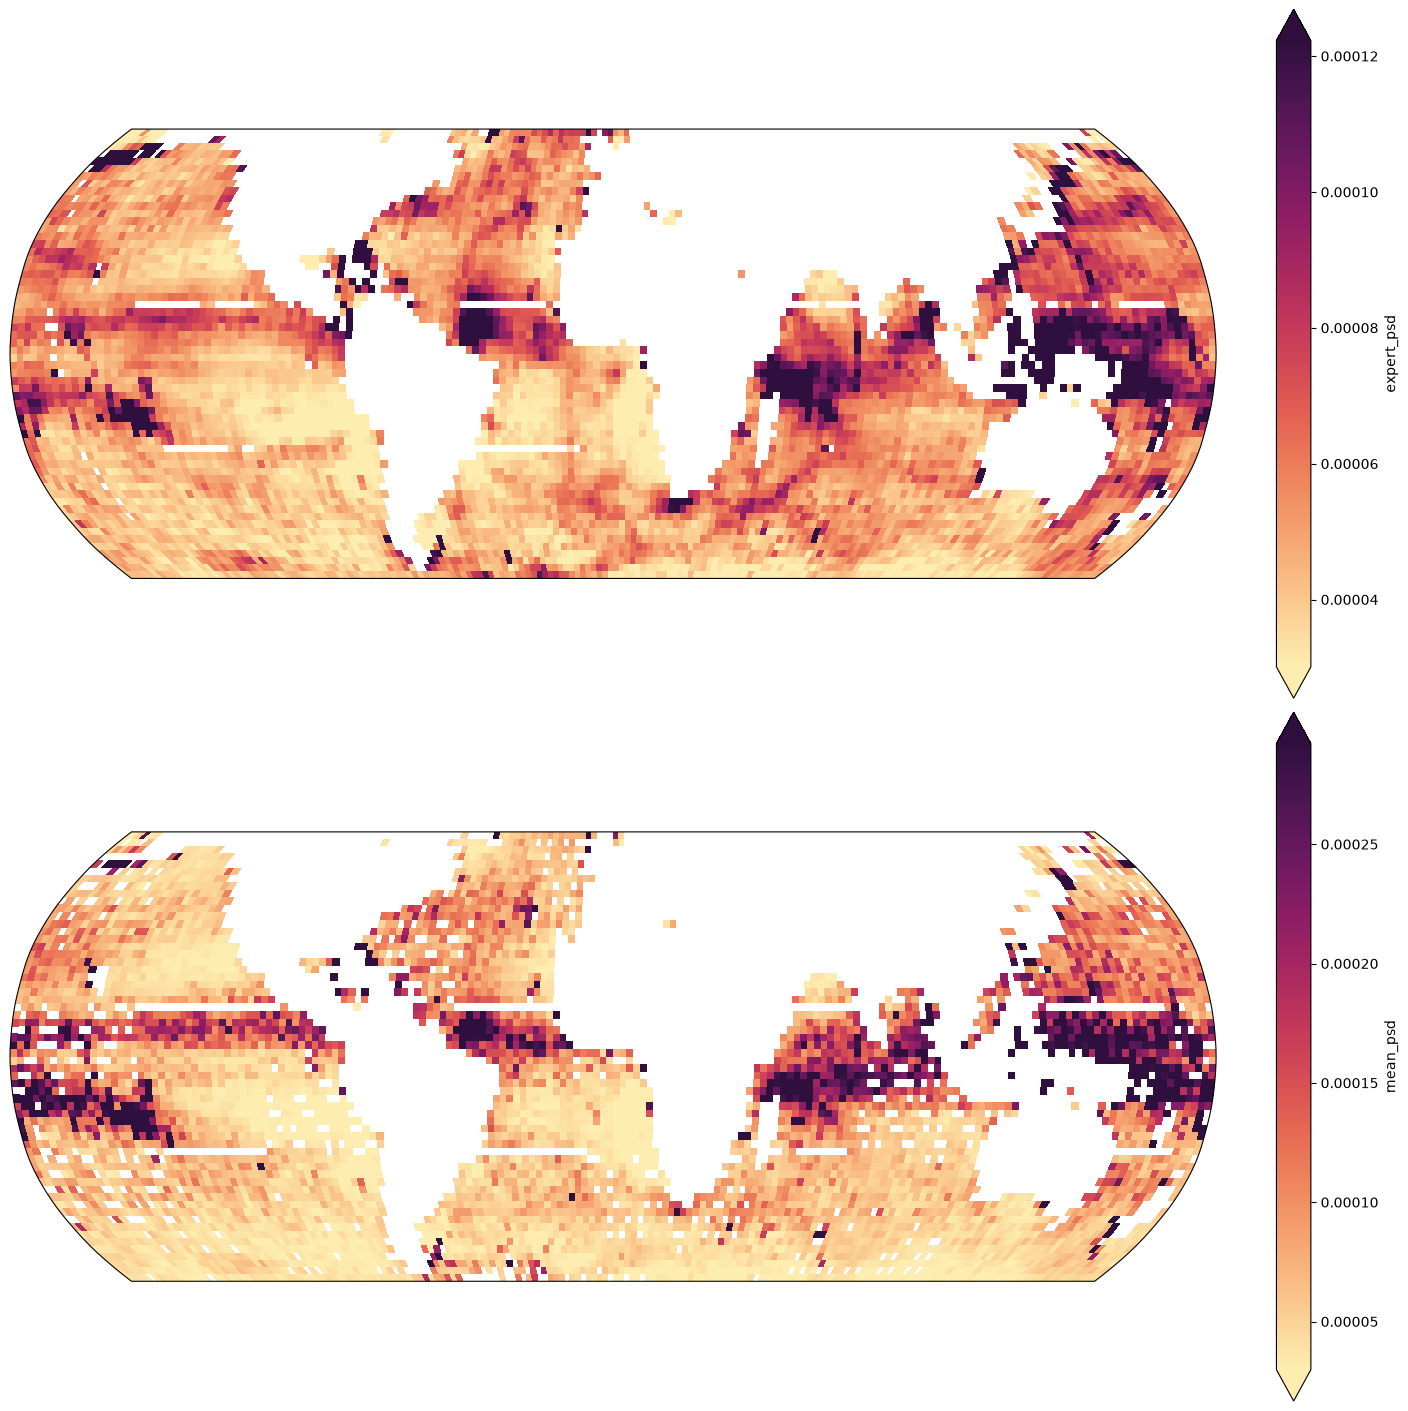

In [19]:
kmin, kmax = 1/50,1/10
energy = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber')
energy_pred = ds_boxes_bis.sel(wavenumber=slice(kmin,kmax)).mean_psd.integrate('wavenumber')
fig, axs = plt.subplots(2,1,figsize=(14,14),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy.plot(ax=axs[0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,5),
            vmax=np.nanpercentile(energy,95),
           cmap=cmocean.cm.matter)
energy_pred.plot(ax=axs[1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy_pred,5),
            vmax=np.nanpercentile(energy_pred,95),
           cmap=cmocean.cm.matter)
axs[0].set_extent([-180,180,-60,60])

## Figures

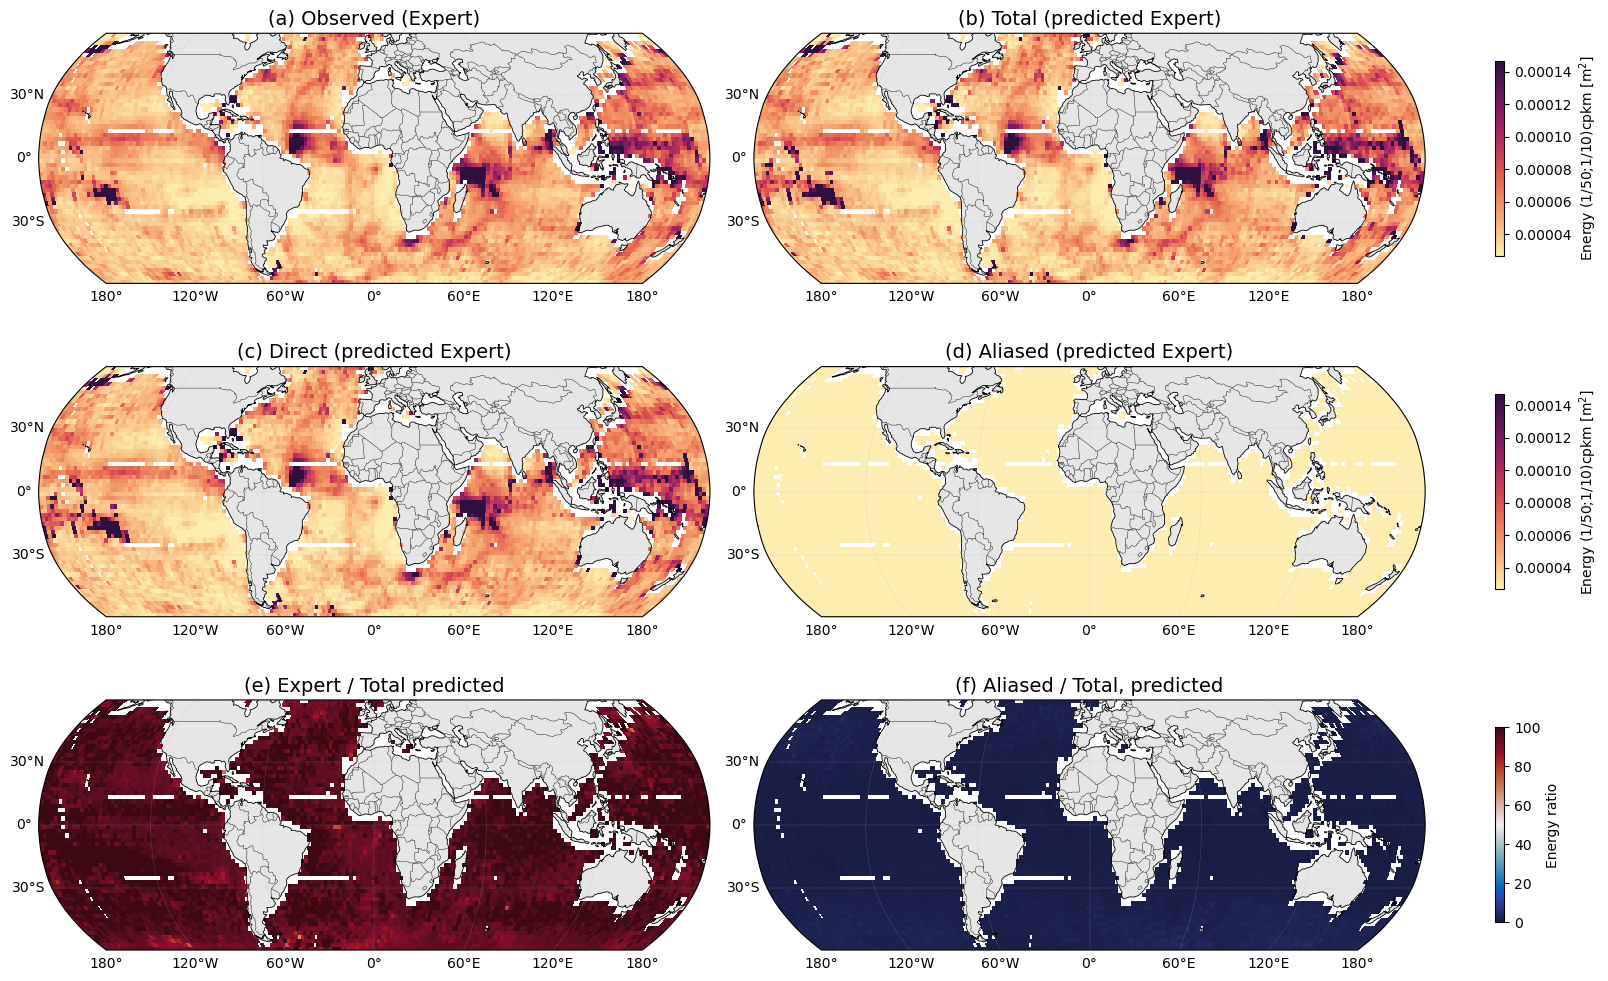

In [16]:
kmin,kmax=1/50,1/10
fig,axs = plt.subplots(3,2,figsize=(16,10),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber')
energy_pred = ds_boxes.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber')
energy_alias = ds_boxes.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber')
energy_direct = ds_boxes.sel(wavenumber=slice(kmin,kmax)).direct_psd.integrate('wavenumber')
energy.plot(ax=axs[0,0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
cb = energy_pred.plot(ax=axs[0,1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
energy_direct.plot(ax=axs[1,0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
(energy_alias).plot(ax=axs[1,1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
(energy_pred/energy*100).plot(ax=axs[2,0],transform=ccrs.PlateCarree(),
            vmin=0,vmax=100,
           cmap=cmocean.cm.balance,add_colorbar=False)
cb1 = (energy_alias/energy_pred*100).plot(ax=axs[2,1],transform=ccrs.PlateCarree(),
            vmin=0,vmax=100,
           cmap=cmocean.cm.balance,add_colorbar=False)
for i in range(3):
    for ax in axs[i,:]:
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
        gl.top_labels = False
        gl.right_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
        gl.xlabel_style = {"size": 10, "color": "black"}
        gl.ylabel_style = {"size": 10, "color": "black"}
        ax.set_extent([-180,180,-60,60])
axs[0,0].set_title(r'(a) Observed (Expert)',fontsize=14)
axs[0,1].set_title(r'(b) Total (predicted Expert)',fontsize=14)
axs[1,1].set_title(r'(d) Aliased (predicted Expert)',fontsize=14)
axs[1,0].set_title(r'(c) Direct (predicted Expert)',fontsize=14)
axs[2,0].set_title(r'(e) Expert / Total predicted',fontsize=14)
axs[2,1].set_title(r'(f) Aliased / Total, predicted',fontsize=14)
plt.colorbar(cb,ax=axs[0,:],shrink=0.6,label=r'Energy (1/50;1/10)cpkm [m$^2$]')
plt.colorbar(cb,ax=axs[1,:],shrink=0.6,label=r'Energy (1/50;1/10)cpkm [m$^2$]')
plt.colorbar(cb1,ax=axs[2,:],shrink=0.6,label=r'Energy ratio')
plt.savefig(f'/Users/zoecas/Documents/paper_figures/expert_aliased_maps.png')

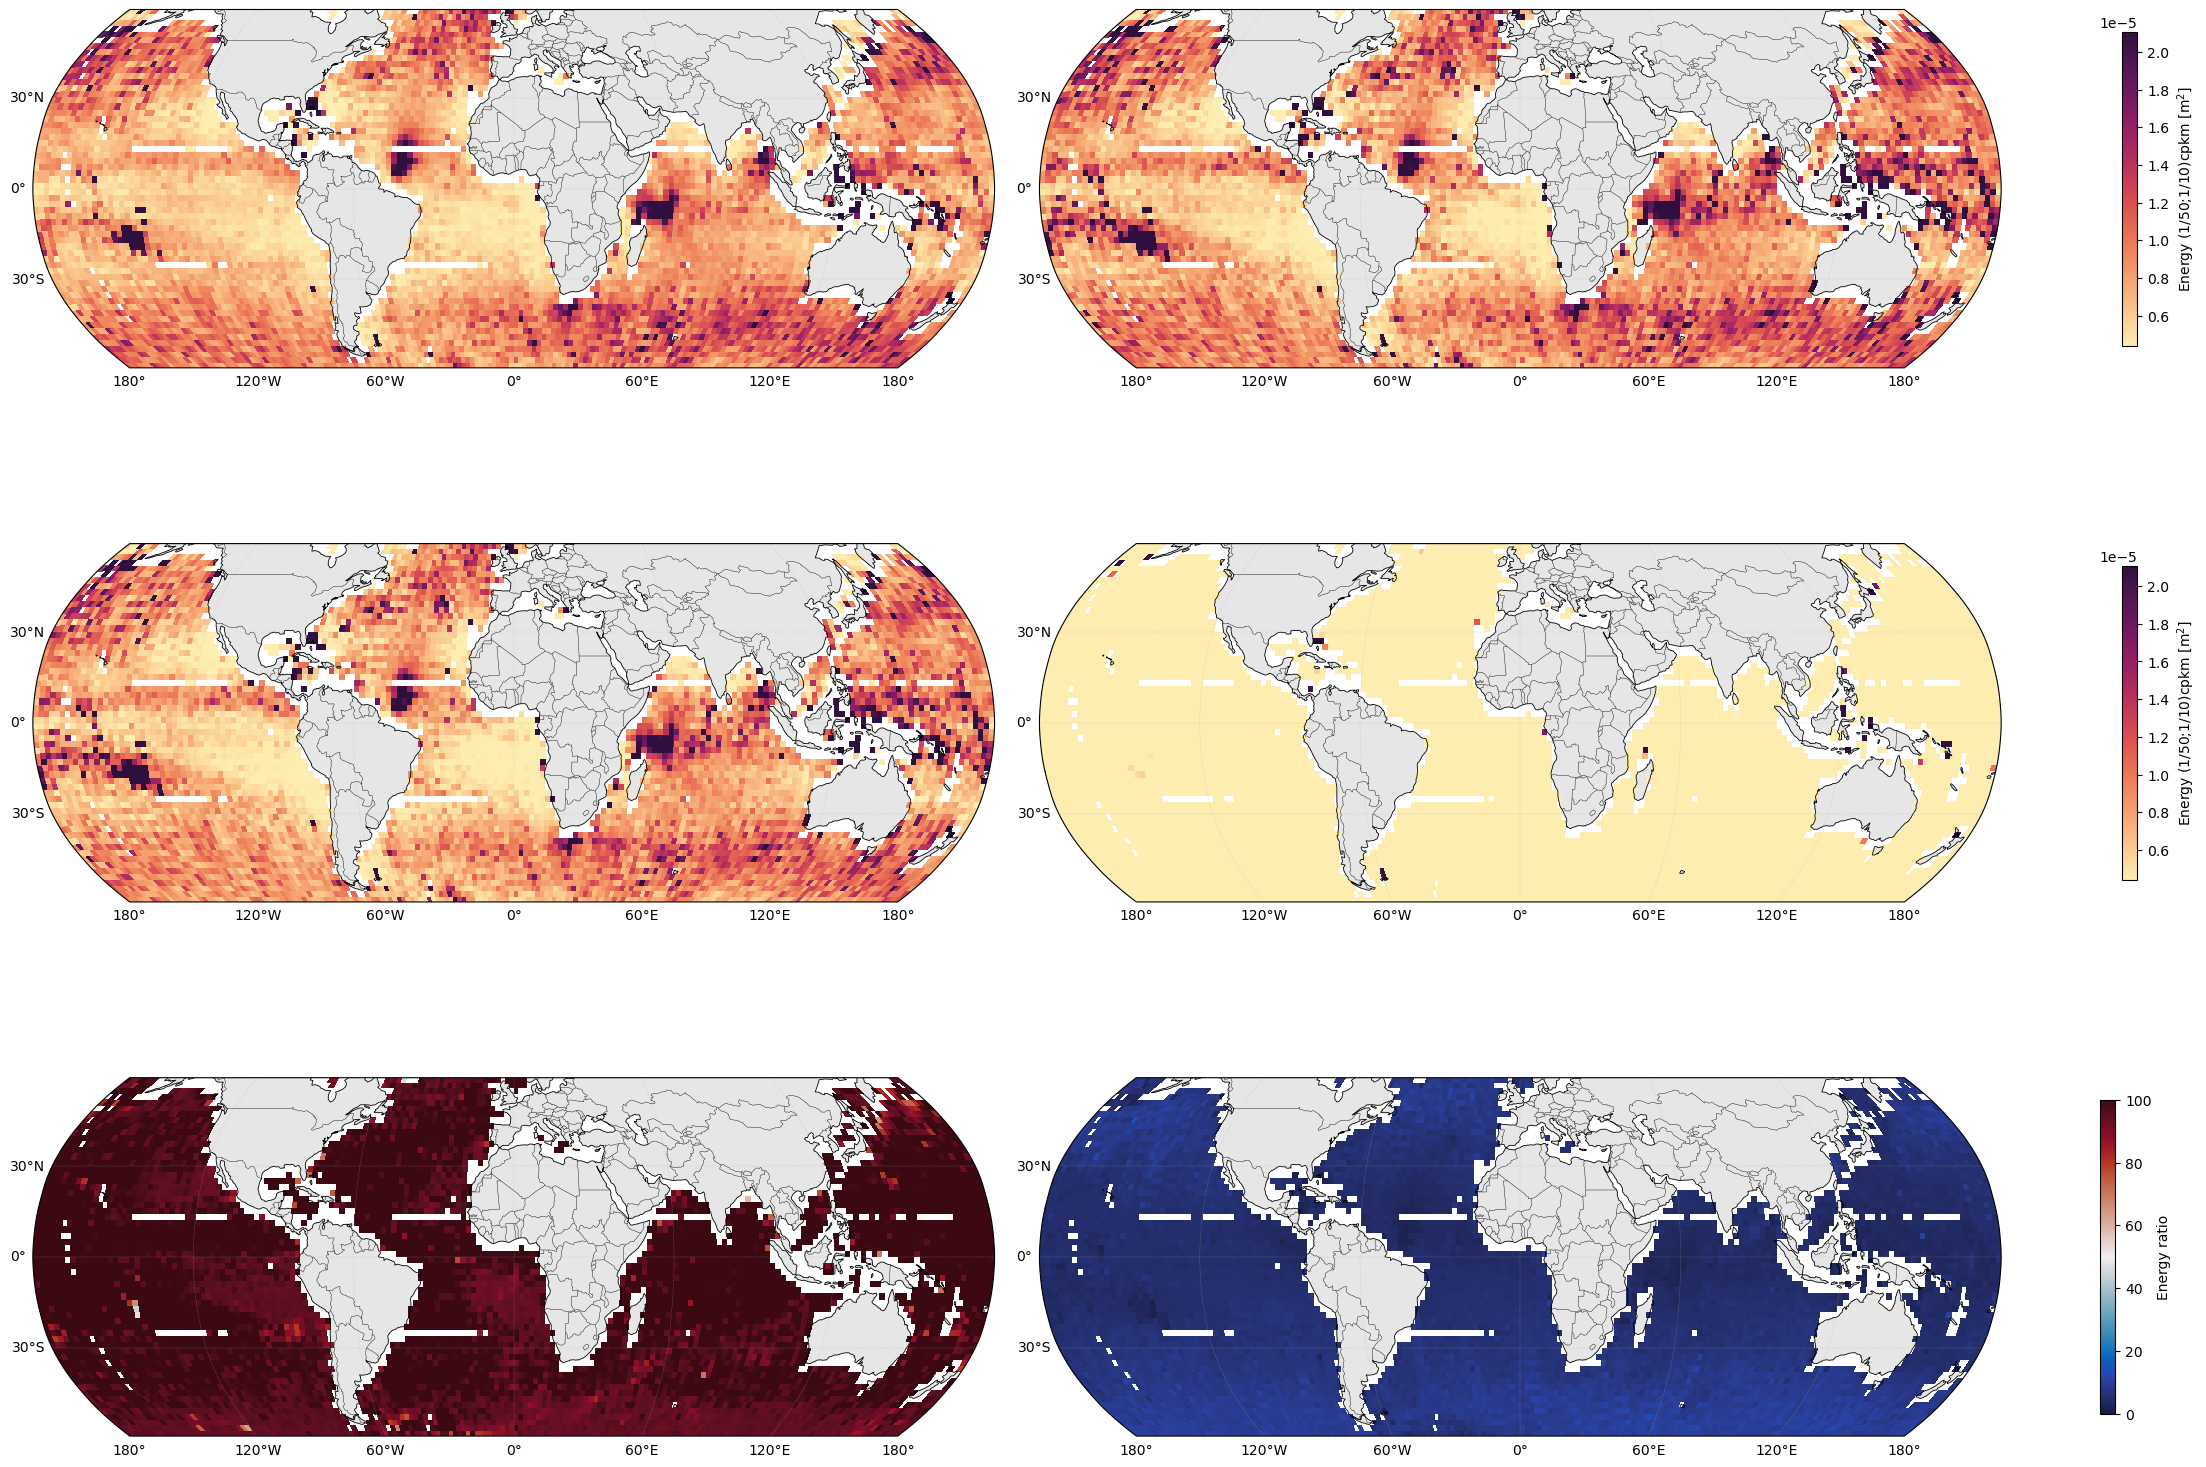

In [17]:
kmin,kmax=1/10,1/5
fig,axs = plt.subplots(3,2,figsize=(22,16),subplot_kw={"projection": ccrs.Robinson()},constrained_layout=True)
energy = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber')
energy_pred = ds_boxes.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber')
energy_alias = ds_boxes.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber')
energy_direct = ds_boxes.sel(wavenumber=slice(kmin,kmax)).direct_psd.integrate('wavenumber')
energy.plot(ax=axs[0,0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
cb = energy_pred.plot(ax=axs[0,1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
energy_direct.plot(ax=axs[1,0],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
(energy_alias).plot(ax=axs[1,1],transform=ccrs.PlateCarree(),
            vmin=np.nanpercentile(energy,2),
            vmax=np.nanpercentile(energy,98),
           cmap=cmocean.cm.matter,add_colorbar=False)
(energy_pred/energy*100).plot(ax=axs[2,0],transform=ccrs.PlateCarree(),
            vmin=0,vmax=100,
           cmap=cmocean.cm.balance,add_colorbar=False)
cb1 = (energy_alias/energy_pred*100).plot(ax=axs[2,1],transform=ccrs.PlateCarree(),
            vmin=0,vmax=100,
           cmap=cmocean.cm.balance,add_colorbar=False)
for i in range(3):
    for ax in axs[i,:]:
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
        gl.top_labels = False
        gl.right_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
        gl.xlabel_style = {"size": 10, "color": "black"}
        gl.ylabel_style = {"size": 10, "color": "black"}
        ax.set_extent([-180,180,-60,60])
plt.colorbar(cb,ax=axs[0,:],shrink=0.6,label=r'Energy (1/50;1/10)cpkm [m$^2$]')
plt.colorbar(cb,ax=axs[1,:],shrink=0.6,label=r'Energy (1/50;1/10)cpkm [m$^2$]')
plt.colorbar(cb1,ax=axs[2,:],shrink=0.6,label=r'Energy ratio')

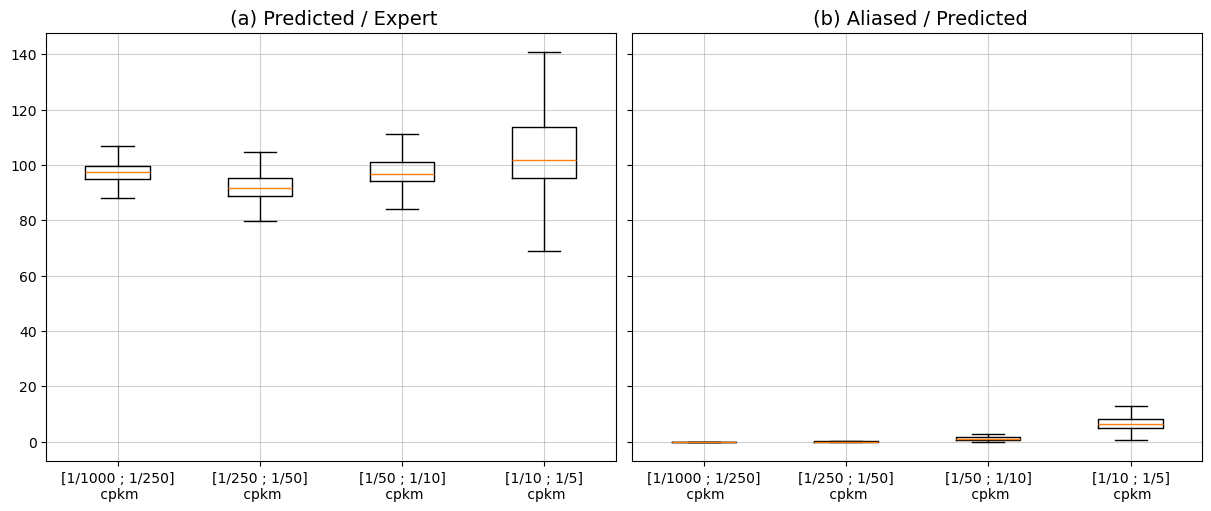

In [18]:
boxplot,boxplot_alias,labels=[],[], []

for kmin,kmax in zip([1/1000,1/250,1/50,1/10], [1/250,1/50,1/10,1/5]):
    energy       = ds_boxes.sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber').values.flatten()
    energy_pred  = ds_boxes.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias = ds_boxes.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber').values.flatten()
    energy_ratio = energy_pred / energy * 100
    alias_ratio  = energy_alias / energy_pred * 100
    boxplot.append(energy_ratio[~np.isnan(energy_ratio)])
    boxplot_alias.append(alias_ratio[~np.isnan(alias_ratio)])
    labels.append(f'[1/{1/kmin:.0f} ; 1/{1/kmax:.0f}]\n cpkm')
#axs[0].boxplot([energy_ratio[~np.isnan(energy_ratio)], alias_ratio[~np.isnan(alias_ratio)]]
#               ,tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)
fig,axs = plt.subplots(1,2,figsize=(12,5), sharey=True, constrained_layout=True)
_=axs[0].boxplot(boxplot,tick_labels=labels,showfliers=False)
_=axs[1].boxplot(boxplot_alias,tick_labels=labels,showfliers=False)
axs[0].set_title(' (a) Predicted / Expert',fontsize=14);
axs[1].set_title(' (b) Aliased / Predicted',fontsize=14)
for ax in axs:
    ax.grid(which='major',alpha=0.6)
plt.savefig(f'/Users/zoecas/Documents/paper_figures/aliased_predicted_ratio.pdf')

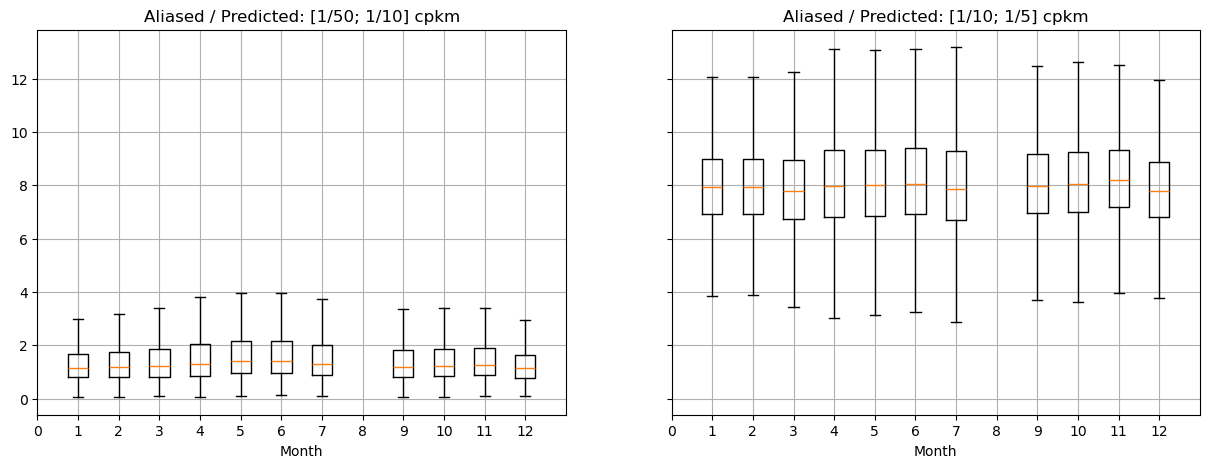

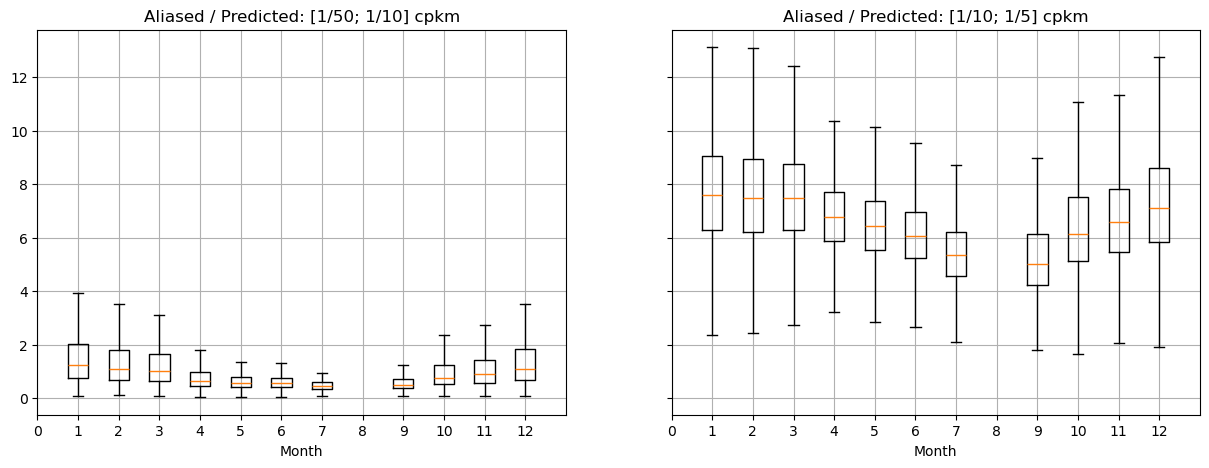

In [25]:
boxplot_alias,boxplot_alias_small=[],[]
kmin,kmax=1/50,1/10
kmax_small = 1/5
for month in range(13):
    #energy       = ds_boxes.where(ds_boxes.month==month,drop=True).sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber').values.flatten()
    ds_m = ds_months_flag.where((ds_months_flag.month==month) &(ds_months_flag.lat_mean<=-35),drop=True)
    energy_pred  = ds_m.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias = ds_m.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber').values.flatten()
    energy_pred_small  = ds_m.sel(wavenumber=slice(kmax,kmax_small)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias_small = ds_m.sel(wavenumber=slice(kmax,kmax_small)).aliased_psd.integrate('wavenumber').values.flatten()
    #energy_ratio = energy_pred / energy * 100
    alias_ratio  = energy_alias / energy_pred * 100
    alias_ratio_small  = energy_alias_small / energy_pred_small * 100
    #boxplot.append(energy_ratio[~np.isnan(energy_ratio)])
    boxplot_alias.append(alias_ratio[~np.isnan(alias_ratio)])
    boxplot_alias_small.append(alias_ratio_small[~np.isnan(alias_ratio_small)])
    #labels.append(f'Month {month:02d}')
#axs[0].boxplot([energy_ratio[~np.isnan(energy_ratio)], alias_ratio[~np.isnan(alias_ratio)]]
#               ,tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)
fig,axs = plt.subplots(1,2,figsize=(15,5),sharey=True)
_=axs[0].boxplot(boxplot_alias,tick_labels=[str(i) for i in range(13)],showfliers=False)
_=axs[1].boxplot(boxplot_alias_small,tick_labels=[str(i) for i in range(13)],showfliers=False)
axs[0].set_title(f'Aliased / Predicted: [1/{int(1/kmin)}; 1/{int(1/kmax)}] cpkm');
axs[1].set_title(f'Aliased / Predicted: [1/{int(1/kmax)}; 1/{int(1/kmax_small)}] cpkm');
for ax in axs:
    ax.grid()
    ax.set_xlabel('Month');
    ax.set_xlim(1,14)

boxplot_alias,boxplot_alias_small=[],[]
kmin,kmax=1/50,1/10
kmax_small = 1/5
for month in range(13):
    #energy       = ds_boxes.where(ds_boxes.month==month,drop=True).sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber').values.flatten()
    ds_m = ds_months_flag.where((ds_months_flag.month==month) &(ds_months_flag.lat_mean>=35),drop=True)
    energy_pred  = ds_m.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias = ds_m.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber').values.flatten()
    energy_pred_small  = ds_m.sel(wavenumber=slice(kmax,kmax_small)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias_small = ds_m.sel(wavenumber=slice(kmax,kmax_small)).aliased_psd.integrate('wavenumber').values.flatten()
    #energy_ratio = energy_pred / energy * 100
    alias_ratio  = energy_alias / energy_pred * 100
    alias_ratio_small  = energy_alias_small / energy_pred_small * 100
    #boxplot.append(energy_ratio[~np.isnan(energy_ratio)])
    boxplot_alias.append(alias_ratio[~np.isnan(alias_ratio)])
    boxplot_alias_small.append(alias_ratio_small[~np.isnan(alias_ratio_small)])
    #labels.append(f'Month {month:02d}')
#axs[0].boxplot([energy_ratio[~np.isnan(energy_ratio)], alias_ratio[~np.isnan(alias_ratio)]]
#               ,tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)
fig,axs = plt.subplots(1,2,figsize=(15,5),sharey=True)
_=axs[0].boxplot(boxplot_alias,tick_labels=[str(i) for i in range(13)],showfliers=False)
_=axs[1].boxplot(boxplot_alias_small,tick_labels=[str(i) for i in range(13)],showfliers=False)
axs[0].set_title(f'Aliased / Predicted: [1/{int(1/kmin)}; 1/{int(1/kmax)}] cpkm');
axs[1].set_title(f'Aliased / Predicted: [1/{int(1/kmax)}; 1/{int(1/kmax_small)}] cpkm');
for ax in axs:
    ax.grid()
    ax.set_xlabel('Month');
    ax.set_xlim(1,14)



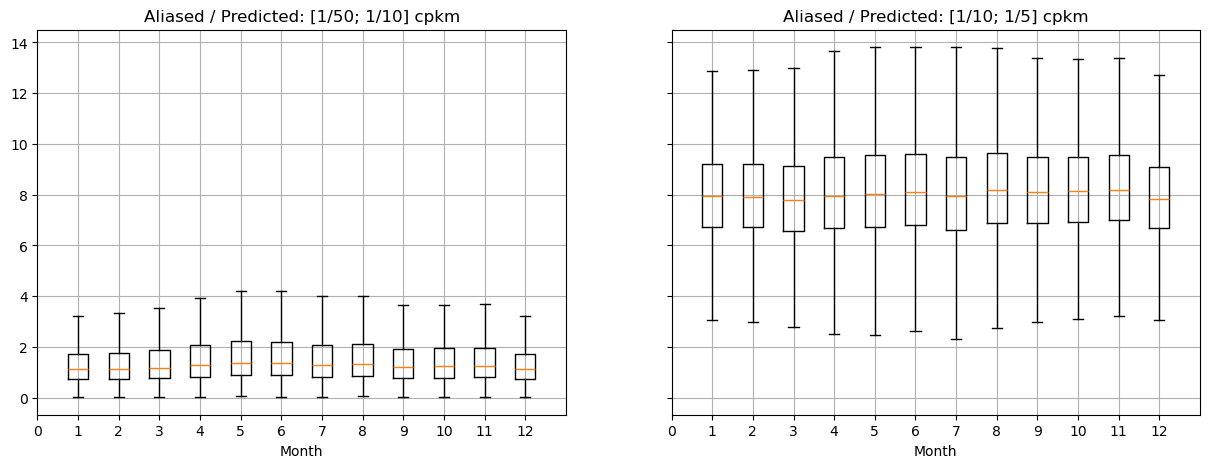

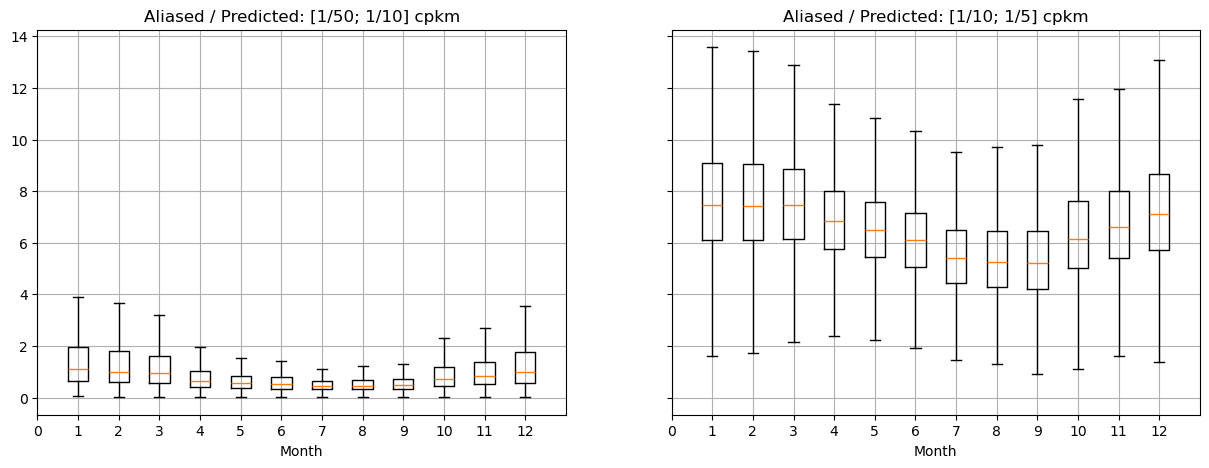

In [24]:
# 250km segments
boxplot_alias,boxplot_alias_small=[],[]
kmin,kmax=1/50,1/10
kmax_small = 1/5
for month in range(13):
    #energy       = ds_boxes.where(ds_boxes.month==month,drop=True).sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber').values.flatten()
    ds_m = ds250_months_flag.where((ds250_months_flag.month==month)  &(ds250_months_flag.lat_mean<=-35),drop=True)
    energy_pred  = ds_m.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias = ds_m.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber').values.flatten()
    energy_pred_small  = ds_m.sel(wavenumber=slice(kmax,kmax_small)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias_small = ds_m.sel(wavenumber=slice(kmax,kmax_small)).aliased_psd.integrate('wavenumber').values.flatten()
    #energy_ratio = energy_pred / energy * 100
    alias_ratio  = energy_alias / energy_pred * 100
    alias_ratio_small  = energy_alias_small / energy_pred_small * 100
    #boxplot.append(energy_ratio[~np.isnan(energy_ratio)])
    boxplot_alias.append(alias_ratio[~np.isnan(alias_ratio)])
    boxplot_alias_small.append(alias_ratio_small[~np.isnan(alias_ratio_small)])
    #labels.append(f'Month {month:02d}')
#axs[0].boxplot([energy_ratio[~np.isnan(energy_ratio)], alias_ratio[~np.isnan(alias_ratio)]]
#               ,tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)
fig,axs = plt.subplots(1,2,figsize=(15,5),sharey=True)
_=axs[0].boxplot(boxplot_alias,tick_labels=[str(i) for i in range(13)],showfliers=False)
_=axs[1].boxplot(boxplot_alias_small,tick_labels=[str(i) for i in range(13)],showfliers=False)
axs[0].set_title(f'Aliased / Predicted: [1/{int(1/kmin)}; 1/{int(1/kmax)}] cpkm');
axs[1].set_title(f'Aliased / Predicted: [1/{int(1/kmax)}; 1/{int(1/kmax_small)}] cpkm');
for ax in axs:
    ax.grid()
    ax.set_xlabel('Month');
    ax.set_xlim(1,14)

boxplot_alias,boxplot_alias_small=[],[]
kmin,kmax=1/50,1/10
kmax_small = 1/5
for month in range(13):
    #energy       = ds_boxes.where(ds_boxes.month==month,drop=True).sel(wavenumber=slice(kmin,kmax)).expert_psd.integrate('wavenumber').values.flatten()
    ds_m = ds250_months_flag.where((ds250_months_flag.month==month) & (ds250_months_flag.lat_mean>=35),drop=True)
    energy_pred  = ds_m.sel(wavenumber=slice(kmin,kmax)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias = ds_m.sel(wavenumber=slice(kmin,kmax)).aliased_psd.integrate('wavenumber').values.flatten()
    energy_pred_small  = ds_m.sel(wavenumber=slice(kmax,kmax_small)).predicted_psd.integrate('wavenumber').values.flatten()
    energy_alias_small = ds_m.sel(wavenumber=slice(kmax,kmax_small)).aliased_psd.integrate('wavenumber').values.flatten()
    #energy_ratio = energy_pred / energy * 100
    alias_ratio  = energy_alias / energy_pred * 100
    alias_ratio_small  = energy_alias_small / energy_pred_small * 100
    #boxplot.append(energy_ratio[~np.isnan(energy_ratio)])
    boxplot_alias.append(alias_ratio[~np.isnan(alias_ratio)])
    boxplot_alias_small.append(alias_ratio_small[~np.isnan(alias_ratio_small)])
    #labels.append(f'Month {month:02d}')
#axs[0].boxplot([energy_ratio[~np.isnan(energy_ratio)], alias_ratio[~np.isnan(alias_ratio)]]
#               ,tick_labels=['Predicted/Expert','Aliased/Predicted'],showfliers=False)
fig,axs = plt.subplots(1,2,figsize=(15,5),sharey=True)
_=axs[0].boxplot(boxplot_alias,tick_labels=[str(i) for i in range(13)],showfliers=False)
_=axs[1].boxplot(boxplot_alias_small,tick_labels=[str(i) for i in range(13)],showfliers=False)
axs[0].set_title(f'Aliased / Predicted: [1/{int(1/kmin)}; 1/{int(1/kmax)}] cpkm');
axs[1].set_title(f'Aliased / Predicted: [1/{int(1/kmax)}; 1/{int(1/kmax_small)}] cpkm');
for ax in axs:
    ax.grid()
    ax.set_xlabel('Month');
    ax.set_xlim(1,14)

## Regional

In [27]:
latc, dlat = 40.0, 5.0
lat_cali = 35
lonc = 315
lon = [290,300,310,320,330,340]
lon_cali = [210,220,230,240]
lat = [0,10,20,30]
dlon = 5.0
lat_masc = -10
lon_masc = [45,55,65,75]
if False:
    ds_lat40  = ds250_expert.where((ds250_expert.lat_mean<=latc+dlat) & (ds250_expert.lat_mean>=latc-dlat),drop=True)
    ds_lat30  = ds250_expert.where((ds250_expert.lat_mean<=lat_cali+dlat) & (ds250_expert.lat_mean>=lat_cali-dlat),drop=True)
    ds_lon310 = ds250_expert.where((ds250_expert.lon_mean<=lonc+dlon) & (ds250_expert.lon_mean>=lonc-dlon),drop=True)
    
    #ds_lat40_swh  = ds250_expert_swh5.where((ds250_expert_swh5.lat_mean<=latc+dlat) & (ds250_expert_swh5.lat_mean>=latc-dlat),drop=True)
    #ds_lat30_swh  = ds250_expert_swh5.where((ds250_expert_swh5.lat_mean<=lat_cali+dlat) & (ds250_expert_swh5.lat_mean>=lat_cali-dlat),drop=True)
    #ds_lon310_swh = ds250_expert_swh5.where((ds250_expert_swh5.lon_mean<=lonc+dlon) & (ds250_expert_swh5.lon_mean>=lonc-dlon),drop=True)
if True:
    ds_lat40  = ds_months_flag.where((ds_months_flag.lat_mean<=latc+dlat) & (ds_months_flag.lat_mean>=latc-dlat),drop=True)
    ds_lat30  = ds_months_flag.where((ds_months_flag.lat_mean<=lat_cali+dlat) & (ds_months_flag.lat_mean>=lat_cali-dlat),drop=True)
    ds_latm10  = ds_months_flag.where((ds_months_flag.lat_mean<=lat_masc+dlat) & (ds_months_flag.lat_mean>=lat_masc-dlat),drop=True)
    ds_lon310 = ds_months_flag.where((ds_months_flag.lon_mean<=lonc+dlon) & (ds_months_flag.lon_mean>=lonc-dlon),drop=True)
    
    #ds_lat40_swh  = ds_expert_swh5.where((ds_expert_swh5.lat_mean<=latc+dlat) & (ds_expert_swh5.lat_mean>=latc-dlat),drop=True)
    #ds_lat30_swh  = ds_expert_swh5.where((ds_expert_swh5.lat_mean<=lat_cali+dlat) & (ds_expert_swh5.lat_mean>=lat_cali-dlat),drop=True)
    #ds_lon310_swh = ds_expert_swh5.where((ds_expert_swh5.lon_mean<=lonc+dlon) & (ds_expert_swh5.lon_mean>=lonc-dlon),drop=True)
colors = cmocean.cm.dense(np.linspace(0.2,1,len(lon)))
colors2 = cmocean.cm.dense(np.linspace(0.2,1,len(lon_cali)))
colors3 = cmocean.cm.dense(np.linspace(0.2,1,len(lon_masc)))
colors1 = cmocean.cm.deep(np.linspace(0.2,1,len(lat)))

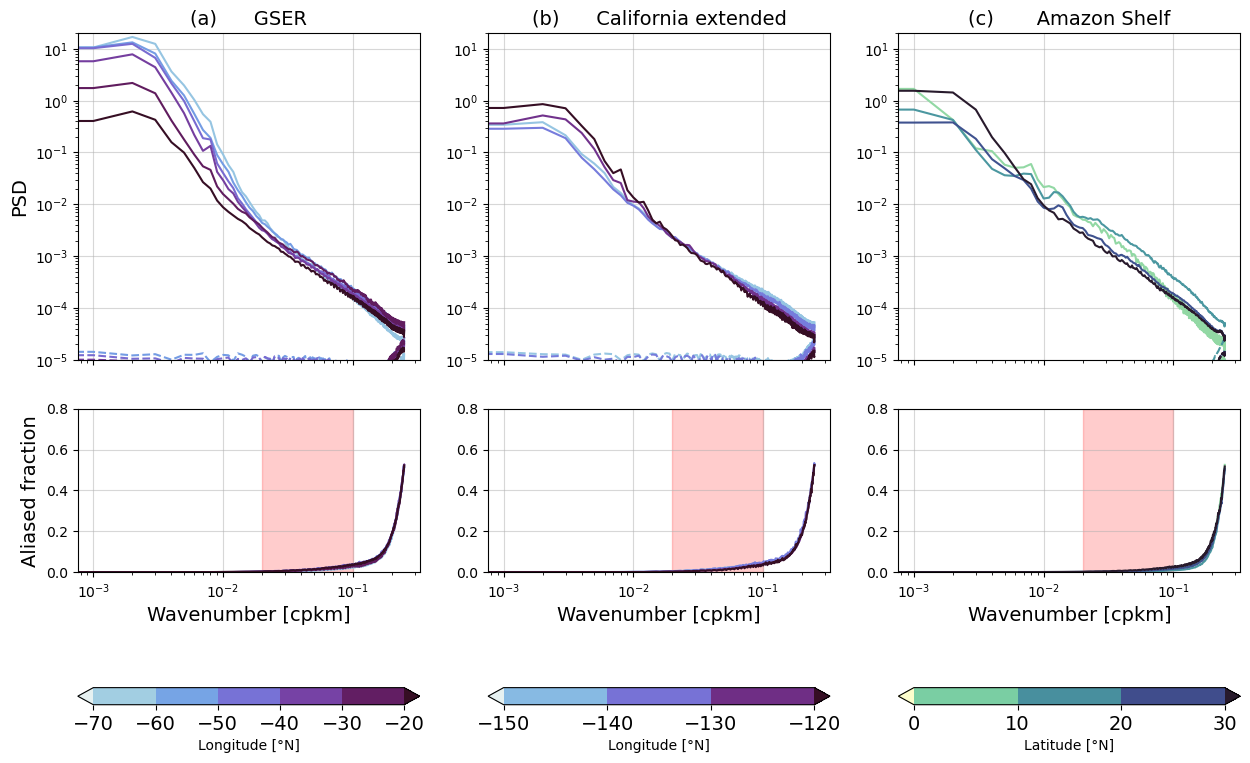

In [29]:
import matplotlib as mpl
fig,axs = plt.subplots(nrows=2, ncols=3, sharex='col', sharey=False,gridspec_kw={'height_ratios': [2, 1]},figsize=(15,10))
for i,l in enumerate(lon):
    _l = ds_lat40.where((ds_lat40.lon_mean<=l+dlon) & (ds_lat40.lon_mean>=l-dlon),drop=True).set_coords('month')
    axs[0,0].loglog(_l.wavenumber,_l.predicted_psd.mean('segment'),c=colors[i])
    axs[0,0].loglog(_l.wavenumber,_l.aliased_psd.mean('segment'),c=colors[i],ls='--')
    axs[1,0].semilogx(_l.wavenumber,_l.aliased_psd.mean('segment')/_l.predicted_psd.mean('segment'),c=colors[i])

for i,l in enumerate(lon_cali):
    _l = ds_lat30.where((ds_lat30.lon_mean<=l+dlon) & (ds_lat30.lon_mean>=l-dlon),drop=True).set_coords('month')
    axs[0,1].loglog(_l.wavenumber,_l.predicted_psd.mean('segment'),c=colors2[i])
    axs[0,1].loglog(_l.wavenumber,_l.aliased_psd.mean('segment'),c=colors2[i],ls='--')
    axs[1,1].semilogx(_l.wavenumber,_l.aliased_psd.mean('segment')/_l.predicted_psd.mean('segment'),c=colors2[i])
    
#for i,l in enumerate(lon_masc):
#    _l = ds_latm10.where((ds_latm10.lon_mean<=l+dlon) & (ds_latm10.lon_mean>=l-dlon),drop=True).set_coords('month')
#    axs[0,3].loglog(_l.wavenumber,_l.predicted_psd.mean('segment'),c=colors3[i])
#    axs[0,3].loglog(_l.wavenumber,_l.aliased_psd.mean('segment'),c=colors3[i],ls='--')
#    axs[1,3].semilogx(_l.wavenumber,_l.aliased_psd.mean('segment')/_l.predicted_psd.mean('segment'),c=colors3[i])
#ax1 = axs[1,2].twinx()
for i,l in enumerate(lat):
    _l = ds_lon310.where((ds_lon310.lat_mean<=l+dlat) & (ds_lon310.lat_mean>=l-dlat),drop=True).set_coords('month')
    axs[0,2].loglog(_l.wavenumber,_l.predicted_psd.mean('segment'),c=colors1[i])
    axs[0,2].loglog(_l.wavenumber,_l.aliased_psd.mean('segment'),c=colors1[i],ls='--')
    axs[1,2].semilogx(_l.wavenumber,_l.aliased_psd.mean('segment')/_l.predicted_psd.mean('segment'),c=colors1[i])
    #ax1.semilogx(_l.wavenumber,_l.predicted_psd.mean('segment')/_l.expert_psd.mean('segment'),c=colors1[i])
    
for ax,title in zip(axs[0,:],['(a)      GSER','(b)      California extended','(c)       Amazon Shelf']):
    ax.grid(True,alpha=0.5)
    ax.set_ylabel('')
    #ax.ticklabel_format(axis='y', style='sci', scilimits=(-4,-4))
    ax.set_xlabel('')
    ax.set_ylim(1e-5,20);
    ax.set_title(title,size=14)
for ax in axs[1,:]:
    ax.set_xlabel('Wavenumber [cpkm]',size=14);
    ax.set_ylim(0.,0.8)
    ax.grid(True,alpha=0.5)
    ax.axvspan(1/50,1/10,color='r',alpha=0.2)
axs[0,0].set_ylabel(r'PSD',size=14)
axs[1,0].set_ylabel(r'Aliased fraction',size=14)
#Customize colorbar
for i, (cm, label,coordinates) in zip(range(3),
                                [(cmocean.cm.dense,"Longitude [°N]",[l-360 for l in lon]),
                                 (cmocean.cm.dense,"Longitude [°N]",[l-360 for l in lon_cali]),
                                 (cmocean.cm.deep,"Latitude [°N]",[l for l in lat])]
                               ):
    norm = mpl.colors.BoundaryNorm(coordinates, cm.N, extend='both')
    colorizer = mpl.colorizer.Colorizer(norm=norm, cmap=cm)
    cb = plt.colorbar(mpl.colorizer.ColorizingArtist(colorizer),
                         ax=axs[:,i], orientation='horizontal',
                         label=label)
    cb.ax.tick_params(labelsize=14)
    #cb.ax.clabel(label,fontsize=14)
plt.savefig('/Users/zoecas/Documents/paper_figures/aliased_regional.png')

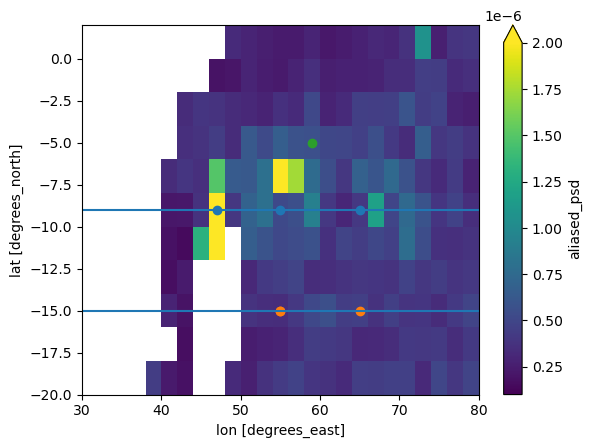

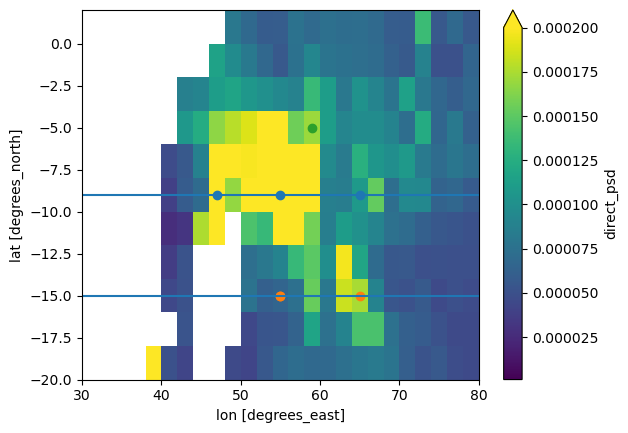

In [31]:
ds_boxes.sel(lat=slice(-20,1),lon=slice(30,80),wavenumber=slice(1/50,1/10)).aliased_psd.integrate('wavenumber').plot(vmin=1e-7,vmax=2e-6)
plt.axhline(-9)
plt.axhline(-15)
plt.scatter([47,55,65],[-9,-9,-9,])
plt.scatter([55,55,65],[-15,-15,-15,])
plt.scatter(59,-5)
plt.figure()
ds_boxes.sel(lat=slice(-20,1),lon=slice(30,80),wavenumber=slice(1/50,1/10)).direct_psd.integrate('wavenumber').plot(vmin=1e-6,vmax=2e-4)
plt.axhline(-9)
plt.axhline(-15)
plt.scatter([47,55,65],[-9,-9,-9,])
plt.scatter([55,55,65],[-15,-15,-15,])
plt.scatter(59,-5)


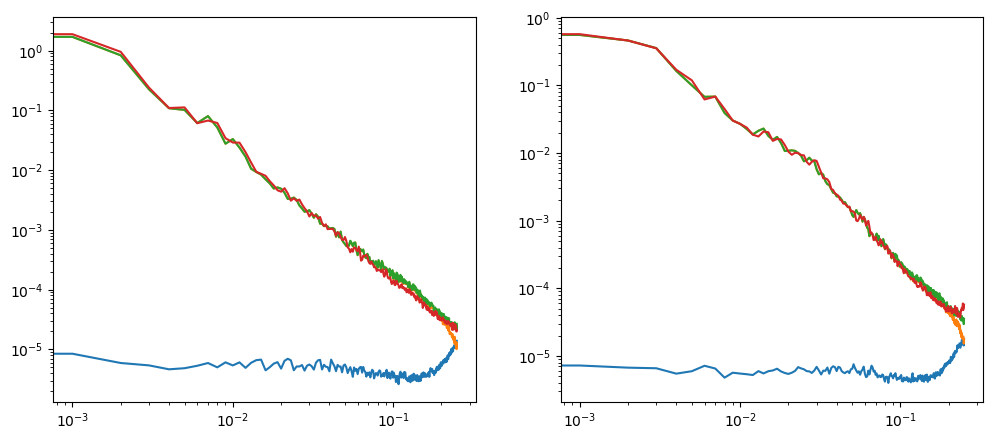

In [32]:
la,lo = -9,45
k = ds_boxes.wavenumber
if False:
    aliased_psd = ds_boxes.sel(lat=la,lon=lo).sel(wavenumber=slice(1/50,1/10)).aliased_psd.integrate('wavenumber')
    direct_psd = ds_boxes.sel(lat=la,lon=lo).sel(wavenumber=slice(1/50,1/10)).direct_psd.integrate('wavenumber')
    predicted_psd = ds_boxes.sel(lat=la,lon=lo).sel(wavenumber=slice(1/50,1/10)).aliased_psd.integrate('wavenumber')
    expert_psd = ds_boxes.sel(lat=la,lon=lo).sel(wavenumber=slice(1/50,1/10)).direct_psd.integrate('wavenumber')
ds_box = ds_boxes.sel(lat=la,lon=lo)
fig,axs = plt.subplots(1,2,figsize=(12,5))
ax=axs[0]
ax.loglog(k,ds_box.aliased_psd)
ax.loglog(k,ds_box.direct_psd)
ax.loglog(k,ds_box.predicted_psd)
ax.loglog(k,ds_box.expert_psd)
la,lo = -15,65
k = ds_boxes.wavenumber
ds_box = ds_boxes.sel(lat=la,lon=lo)
ax=axs[1]
ax.loglog(k,ds_box.aliased_psd)
ax.loglog(k,ds_box.direct_psd)
ax.loglog(k,ds_box.predicted_psd)
#ax.axvline(1/50)
ax.loglog(k,ds_box.expert_psd)

In [35]:
la,lo = -15,65
ds_box_seg = ds_months_flag.where((ds_months_flag.lat_mean<=la+1) & (ds_months_flag.lat_mean>=la-1) &
                        (ds_months_flag.lon_mean<=lo+1) & (ds_months_flag.lon_mean>=lo-1), drop=True)

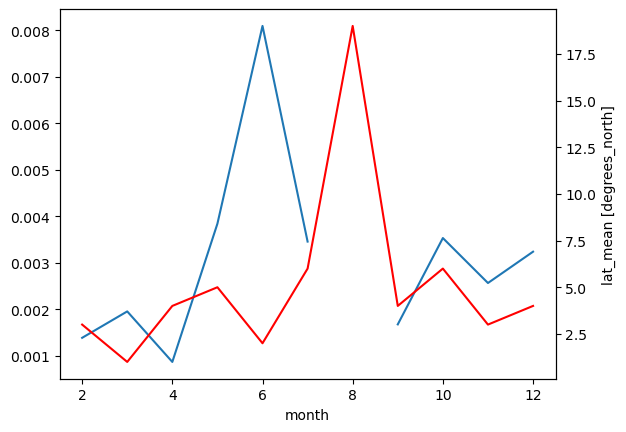

In [36]:
kmin,kmax=1/50,1/10
energy = ds_box_seg.set_coords('month').groupby('month').mean().sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
(energy.aliased_psd/energy.predicted_psd).plot()
plt.twinx()
ds_box_seg.set_coords('month').groupby('month').count().lat_mean.plot(c='r')

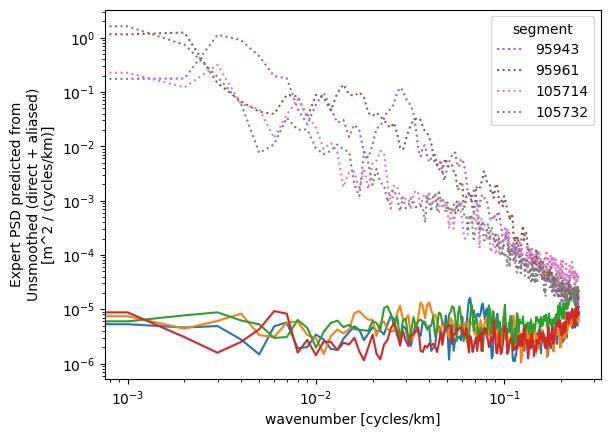

In [37]:
ds_box_seg.where(ds_box_seg.month==4,drop=True).aliased_psd.plot(hue='segment',xscale='log',yscale='log')
ds_box_seg.where(ds_box_seg.month==4,drop=True).predicted_psd.plot(hue='segment',xscale='log',yscale='log',ls=':')

In [38]:
s= 95938
print('Segment info')
print(f'cycle: {ds_box_seg.sel(segment=s).cycle.values}, pass: {ds_box_seg.sel(segment=s).pass_number.values}, swath: {ds_box_seg.sel(segment=s).swath.values}')
print(f'lat: {ds_box_seg.sel(segment=s).lat_mean.values},lon: {ds_box_seg.sel(segment=s).lon_mean.values}')

Segment info


KeyError: "not all values found in index 'segment'. Try setting the `method` keyword argument (example: method='nearest')."

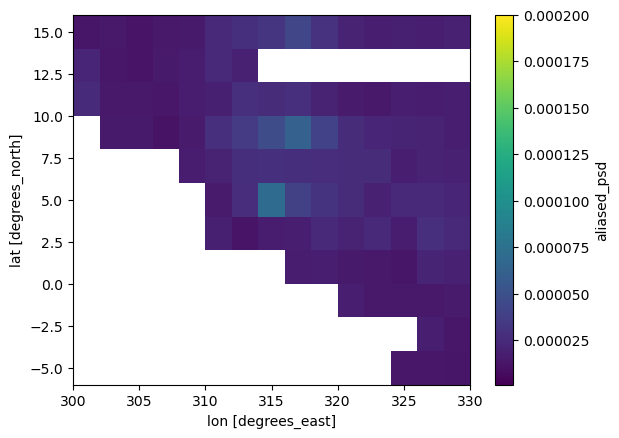

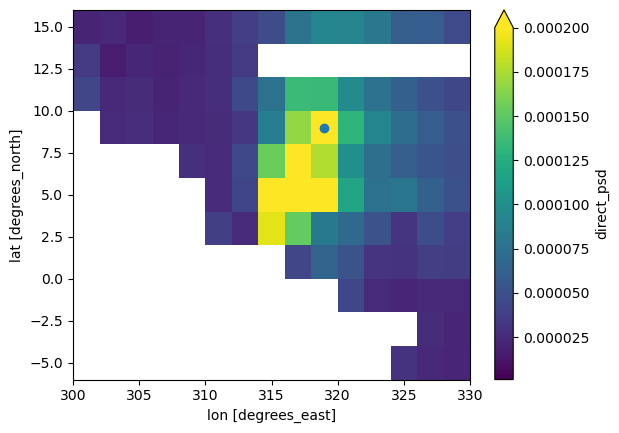

In [283]:
ds_boxes.sel(lat=slice(-5,15),lon=slice(300,330),wavenumber=slice(1/50,1/10)).aliased_psd.integrate('wavenumber').plot(vmin=1e-6,vmax=2e-4)
plt.axhline(-9)
plt.axhline(-15)
#plt.scatter([47,55,65],[-9,-9,-9,])
#plt.scatter([55,55,65],[-15,-15,-15,])
#plt.scatter(59,-5)
plt.figure()
ds_boxes.sel(lat=slice(-5,15),lon=slice(300,330),wavenumber=slice(1/50,1/10)).direct_psd.integrate('wavenumber').plot(vmin=1e-6,vmax=2e-4)
plt.axhline(-9)
plt.axhline(-15)
#plt.scatter([47,55,65],[-9,-9,-9,])
#plt.scatter([55,55,65],[-15,-15,-15,])
plt.scatter(319,9)


In [39]:
la,lo = 9,319
ds_box_sega = ds_months_flag.where((ds_months_flag.lat_mean<=la+1) & (ds_months_flag.lat_mean>=la-1) &
                        (ds_months_flag.lon_mean<=lo+1) & (ds_months_flag.lon_mean>=lo-1), drop=True)

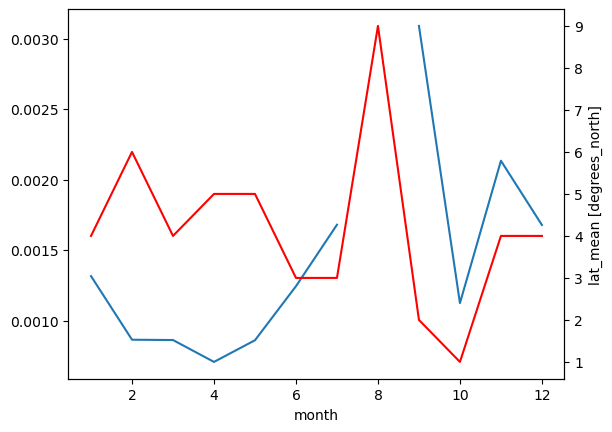

In [40]:
kmin,kmax=1/50,1/10
energy = ds_box_sega.set_coords('month').groupby('month').mean().sel(wavenumber=slice(kmin,kmax)).integrate('wavenumber')
(energy.aliased_psd/energy.predicted_psd).plot()
plt.twinx()
ds_box_sega.set_coords('month').groupby('month').count().lat_mean.plot(c='r')

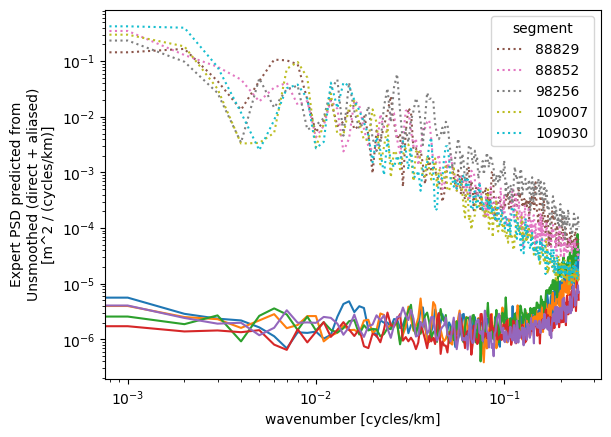

In [41]:
ds_box_sega.where(ds_box_sega.month==4,drop=True).aliased_psd.plot(hue='segment',xscale='log',yscale='log')
ds_box_sega.where(ds_box_sega.month==4,drop=True).predicted_psd.plot(hue='segment',xscale='log',yscale='log',ls=':')

In [42]:
s= 109007
print('Segment info')
print(f'cycle: {ds_box_sega.sel(segment=s).cycle.values}, pass: {ds_box_sega.sel(segment=s).pass_number.values}, swath: {ds_box_sega.sel(segment=s).swath.values}')
print(f'lat: {ds_box_sega.sel(segment=s).lat_mean.values},lon: {ds_box_sega.sel(segment=s).lon_mean.values}')

Segment info
cycle: 14.0, pass: 199.0, swath: left
lat: 9.953905693442602,lon: 318.1842395465956


In [292]:
# Loading swaths of interest
from pathlib import Path

def find_swot_file(root, product, cycle, pass_num, month=None):
    """product: 'Expert', 'Unsmoothed' or 'Basic'. Returns the path (latest version if several)."""
    root = Path(root)
    pattern = f"SWOT_L2_LR_SSH_{product}_{cycle:03d}_{pass_num:03d}_*.nc"
    # restrict to a month subfolder if your data are organised that way, e.g. root/2024/03
    folder = root / month if month is not None else root
    files = sorted(folder.rglob(pattern))
    if not files:
        raise FileNotFoundError(f"No {product} file for cycle {cycle}, pass {pass_num} in {folder}")
    if len(files) > 1:
        print(f"{len(files)} matches, using the last one:\n  " + "\n  ".join(map(str, files)))
    return files[-1]


month = 4
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=13, pass_num=413)
expert = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=14, pass_num=199)
expert1 = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=13, pass_num=400)
expert2 = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=14, pass_num=94)
expert3 = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=13, pass_num=316)
expert4 = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=13, pass_num=482)
expert4 = xr.open_dataset(FILEPATH)
FILEPATH =find_swot_file(DATA_DIR+f"SWOT_L2_LR_SSH_Expert_{month:02d}24/", "Expert", cycle=14, pass_num=176)
expert5 = xr.open_dataset(FILEPATH)
#FILENAME = f'SWOT_L2_LR_SSH_Expert_{month:02d}24/SWOT_L2_LR_SSH_Expert_{cycle:03d}_{passe:03d}_20240401T014537_20240401T023704_PGD0_01.nc'

In [233]:
FILEPATH

PosixPath('/Volumes/PortableSSD/SWOT_L2_LR_SSH_Expert_0424/SWOT_L2_LR_SSH_Expert_014_176_20240423T172304_20240423T181432_PGD0_01.nc')

In [234]:
ex=expert
ssha = ex.where(ex.ssha_karin_2_qual==0).ssha_karin_2 + ex.where(ex.ssha_karin_2_qual==0).height_cor_xover
latitude = ex.latitude
longitude = ex.longitude
vmax = np.nanpercentile(ssha,97)
vmin = np.nanpercentile(ssha,3)

In [294]:
ex1=expert1
ssha1 = ex.where(ex1.ssha_karin_2_qual==0).ssha_karin_2 + ex1.where(ex1.ssha_karin_2_qual==0).height_cor_xover
latitude1 = ex1.latitude
longitude1 = ex1.longitude
vmax = np.nanpercentile(ssha1,97)
vmin = np.nanpercentile(ssha1,3)

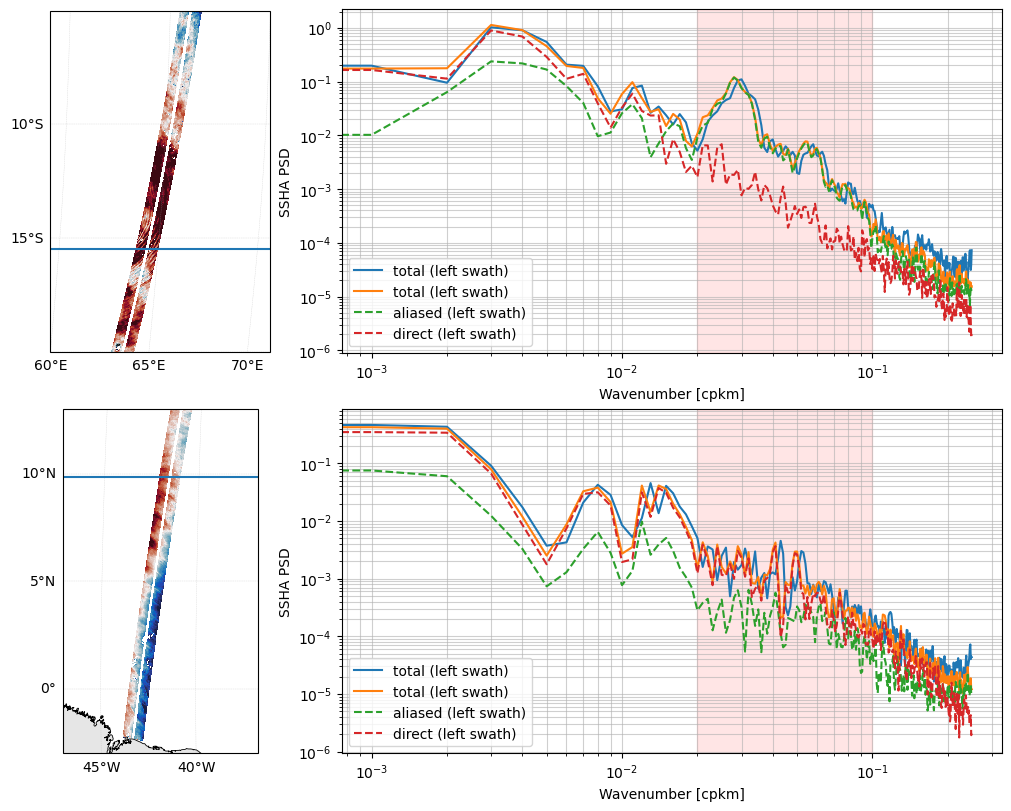

In [317]:
fig = plt.figure(figsize=(10,8),constrained_layout=True)
spec = gridspec.GridSpec(ncols=4, nrows=2, figure=fig)
for i,_ex,ds_box,s,bounds,latc in zip(range(2),[ex,ex1],[ds_box_seg,ds_box_sega],[95920,109007],[[60,70,-20,-5],[313,323,-3,13]],[-15.4,9.8]):
    ax = fig.add_subplot(spec[i,0],projection=ccrs.Robinson())
    ssha = _ex.where(_ex.ssha_karin_2_qual==0).ssha_karin_2 + _ex.where(_ex.ssha_karin_2_qual==0).height_cor_xover
    latitude = _ex.latitude
    longitude = _ex.longitude
    vmax = np.nanpercentile(ssha,95)
    vmin = np.nanpercentile(ssha,5)
    ax.pcolormesh(longitude,latitude,ssha,transform=ccrs.PlateCarree(),vmax=vmax,vmin=vmin,cmap=cmocean.cm.balance)
    if True:    
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
        gl.top_labels = False
        gl.right_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 5))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 5))
        gl.xlabel_style = {"size": 10, "color": "black"}
        gl.ylabel_style = {"size": 10, "color": "black"}
    ax.set_extent(bounds)
    line = ax.plot([bounds[0]-2,bounds[0]+5,bounds[1]+2],[latc,latc,latc],transform=ccrs.PlateCarree())
    ax = fig.add_subplot(spec[i,1:])
    #ax.loglog(ds_box_seg.sel(segment=s).wavenumber,ds_box_seg.sel(segment=s).expert_psd)
    ax.loglog(ds_box.sel(segment=s).wavenumber,ds_box.sel(segment=s).expert_psd,label='total (left swath)')
    ax.loglog(ds_box.sel(segment=s).wavenumber,ds_box.sel(segment=s).predicted_psd,label='total (left swath)')
    ax.loglog(ds_box.sel(segment=s).wavenumber,ds_box.sel(segment=s).aliased_psd,ls='--',label='aliased (left swath)')
    ax.loglog(ds_box.sel(segment=s).wavenumber,ds_box.sel(segment=s).direct_psd,ls='--',label='direct (left swath)')
    ax.set_ylabel(r'SSHA PSD');ax.legend();
    ax.grid(which='both',alpha=0.6)
    ax.set_xlabel(r'Wavenumber [cpkm]')
    ax.axvspan(1/50,1/10,color='r',alpha=0.1)
#plt.savefig('/Users/zoecas/Documents/paper_figures/swath_mascarene.png')

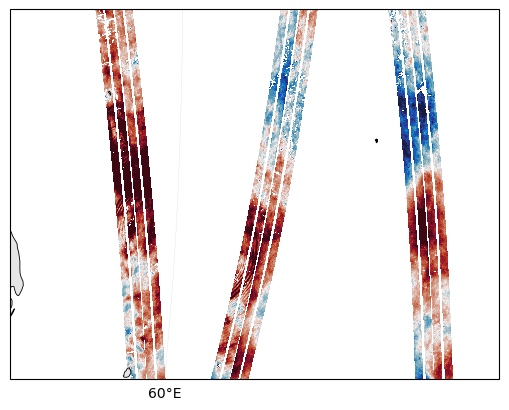

In [197]:
fig,ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})
for ex in [expert,expert1,expert2,expert3,expert4,expert5]:
    ssha = ex.where(ex.ssha_karin_2_qual==0).ssha_karin_2 + ex.where(ex.ssha_karin_2_qual==0).height_cor_xover
    latitude = ex.latitude
    longitude = ex.longitude
    #vmax = np.nanpercentile(ssha,99)
    #vmin = np.nanpercentile(ssha,1)
    ax.pcolormesh(longitude,latitude,ssha,transform=ccrs.PlateCarree(),vmax=vmax,vmin=vmin,cmap=cmocean.cm.balance)
if True:    
    ax.set_global()
    ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.xlabel_style = {"size": 10, "color": "black"}
    gl.ylabel_style = {"size": 10, "color": "black"}

#ax.scatter(longitude.values,latitude.values,c=ssha,transform=ccrs.PlateCarree(),vmax=vmax,vmin=vmin)
#ax.axhline(-9,projection=ccrs.PlateCarree())
ax.set_extent([50,80,-20,0])

#plt.ylim(-20,10)
#plt.xlim(40,80)

In [109]:
ds_masc = ds_months_flagged.where((ds_months_flagged.lat_mean<=10) & (ds_months_flagged.lat_mean>=-20) &
                       (ds_months_flagged.lon_mean<=80) & (ds_months_flagged.lon_mean>=40), drop=True)

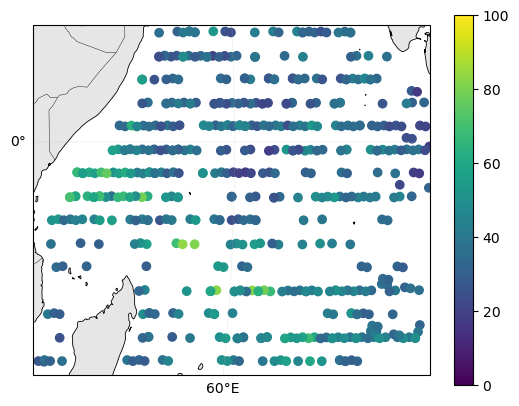

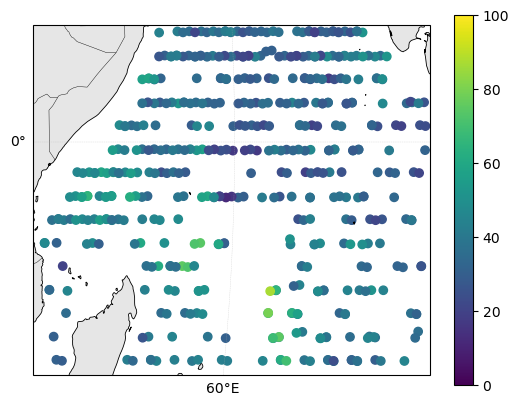

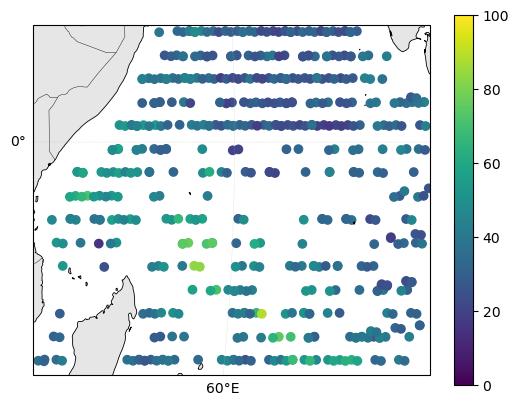

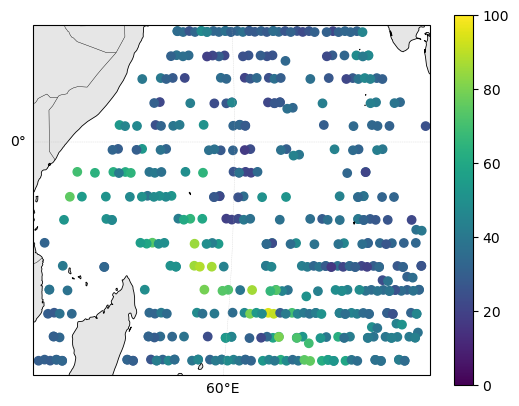

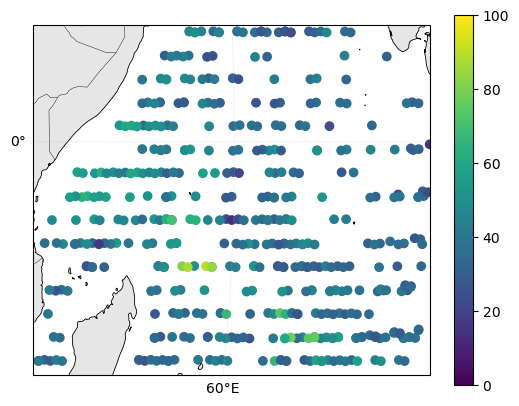

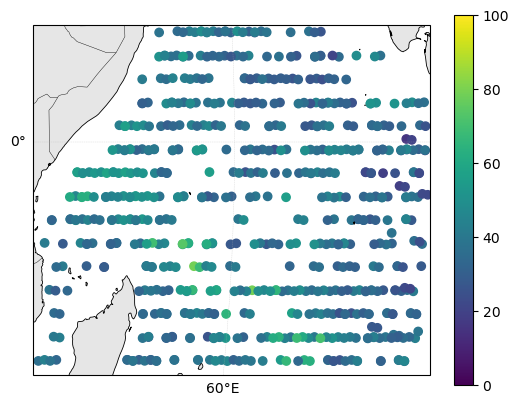

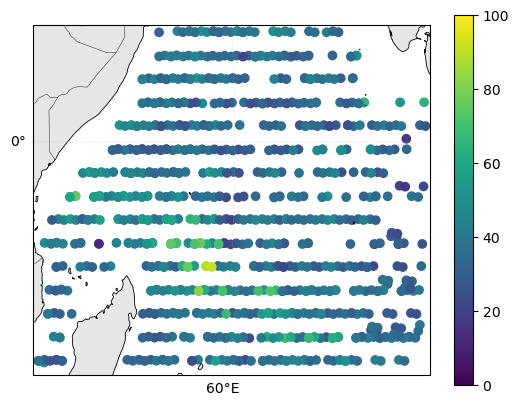

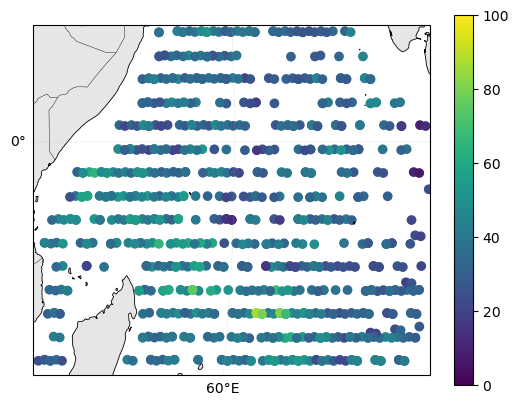

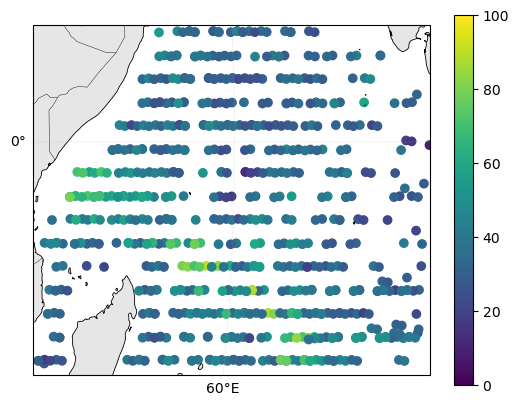

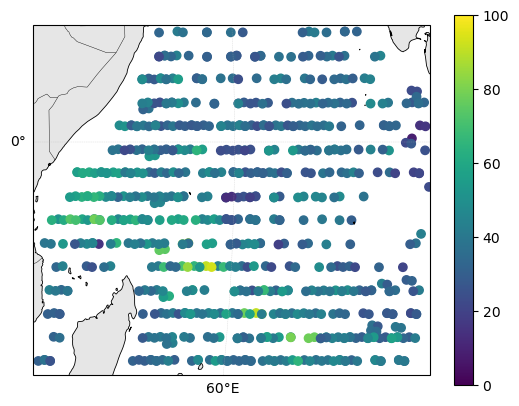

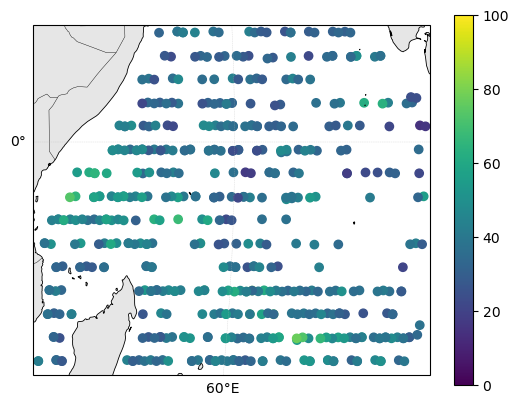

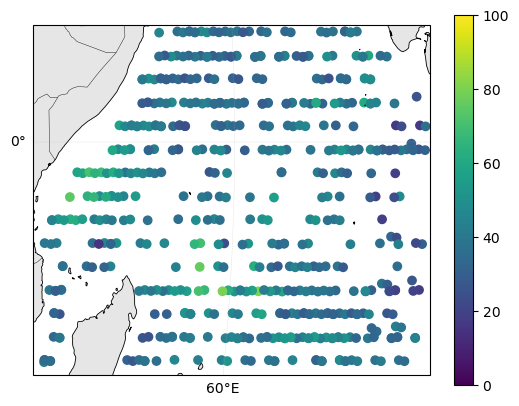

In [145]:
for m in np.arange(1,13):
    fig,ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})
    if True:    
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor="0.9", edgecolor="none")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.BORDERS, linewidth=0.3)
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, linestyle="--", alpha=0.5)
        gl.top_labels = False
        gl.right_labels = False
        gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
        gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
        gl.xlabel_style = {"size": 10, "color": "black"}
        gl.ylabel_style = {"size": 10, "color": "black"}
    _ = ds_masc.where(ds_masc.month==m).sel(wavenumber=slice(1/50,1/10)).integrate('wavenumber')
    cb = plt.scatter(ds_masc.lon_mean,ds_masc.lat_mean,c=(_.aliased_psd/_.predicted_psd)*100,vmax=100,vmin=0,transform=ccrs.PlateCarree())
    plt.colorbar(cb,ax=ax)
    ax.set_extent([40,80,-20,10])

## Comparison to GDP / LLC

In [44]:
#--------- Direct vs GDP -------------------
GDP_FILE = "/Volumes/PortableSSD/gdp_energy.nc"
ds_gdp = xr.open_dataset(GDP_FILE)
ds_gdp = ds_gdp.assign_coords({'lon':(ds_gdp.lon%360)}).sortby('lon')

In [45]:
from scipy.ndimage import binary_dilation


import numpy as np, warnings

def make_k_edges(k, n_bands=20, min_bins=2):
    """
    Log-spaced band edges built from the actual wavenumber grid ``k`` (k > 0):
    every band holds at least ``min_bins`` bins, the lowest bin and the last
    (Nyquist) bin are included, and edges lie halfway between grid points.
    """
    k = np.asarray(k, float); k = k[k > 0]
    mid = np.sqrt(k[:-1] * k[1:])
    edges = np.r_[k[0] * (k[0] / mid[0]), mid, k[-1] * (k[-1] / mid[-1])]
    wanted = np.geomspace(edges[0], edges[-1], n_bands + 1)
    idx = np.unique(np.searchsorted(edges, wanted))          # snap to bin boundaries
    out = [idx[0]]
    for i in idx[1:]:
        if i - out[-1] >= min_bins:
            out.append(i)
    if out[-1] != idx[-1]:                                    # last band absorbs the remainder
        out[-1] = idx[-1]
    return edges[out]


def band_average_k(psd, k_edges, verbose=True):
    """
    psd: (lat, lon, wavenumber) -> (lat, lon, kc). Bands are [lo, hi) except the
    last one, which is closed so the highest wavenumber is included.
    Empty bands are NOT dropped silently: they are reported (and warned about).
    """
    k = psd['wavenumber'].values
    k_edges = np.asarray(k_edges, float)
    out, kc, n_bins, empty = [], [], [], []
    for b, (lo, hi) in enumerate(zip(k_edges[:-1], k_edges[1:])):
        last = b == len(k_edges) - 2
        sel = (k >= lo) & ((k <= hi) if last else (k < hi))
        if not sel.any():
            empty.append((lo, hi)); continue
        out.append(psd.isel(wavenumber=sel).mean('wavenumber', skipna=True).values)
        kc.append(float(np.exp(np.mean(np.log(k[sel])))))     # geometric mean k of the bins used
        n_bins.append(int(sel.sum()))
    outside = int(((k < k_edges[0]) | (k > k_edges[-1])).sum())
    if empty:
        warnings.warn(f'{len(empty)} empty k band(s) dropped: ' +
                      ', '.join(f'{lo:.4f}-{hi:.4f}' for lo, hi in empty))
    if outside:
        warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '
                      f'(grid {k.min():.4f}-{k.max():.4f}, edges {k_edges[0]:.4f}-{k_edges[-1]:.4f})')
    if verbose:
        print(f'k bands: {len(kc)} kept / {len(k_edges) - 1} requested; bins per band: {n_bins}')
    return np.stack(out, axis=-1), np.array(kc)


def lat_band_percentile(field, lat, band_deg=None):
    """Percentile rank (0..1); per latitude band, or global if band_deg is None."""
    out = np.full(field.shape, np.nan)
    if band_deg is None:
        m = np.isfinite(field)
        ranks = np.empty(m.sum())
        ranks[np.argsort(field[m], kind='stable')] = np.arange(m.sum())
        out[m] = (ranks + 0.5) / m.sum()
        return out
    band = np.floor(lat / band_deg).astype(int)
    for b in np.unique(band):
        rows = np.where(band == b)[0]
        vals = field[rows, :]
        m = np.isfinite(vals)
        if m.sum() < 5:
            continue
        ranks = np.empty(m.sum())
        ranks[np.argsort(vals[m], kind='stable')] = np.arange(m.sum())
        p = np.full(vals.shape, np.nan)
        p[m] = (ranks + 0.5) / m.sum()
        out[rows, :] = p
    return out


def _metrics(Ps, Pr, top_q, tol):
    """Rank correlation and hotspot lift between two percentile maps."""
    v = np.isfinite(Ps) & np.isfinite(Pr)
    if v.sum() < 20:
        return np.nan, np.nan, int(v.sum())
    a, b = Ps[v], Pr[v]
    r = np.corrcoef(a, b)[0, 1]
    A = np.zeros(Ps.shape, bool); A[v] = Ps[v] >= 1 - top_q
    B = np.zeros(Pr.shape, bool); B[v] = Pr[v] >= 1 - top_q
    if tol > 0:
        B = binary_dilation(B, iterations=tol) & np.isfinite(Pr)
    hit = (A & B).sum() / max(A.sum(), 1)
    expected = (B & v).sum() / v.sum()
    return r, (hit / expected if expected > 0 else np.nan), int(v.sum()), expected


def pattern_match_curve(swot_psd, ref, k_edges, band_deg=2.0, top_q=0.05,
                        tol=0, n_null=200, seed=0, grid_tol_deg=1.0):
    """
    Pattern agreement between SWOT PSD (lat, lon, wavenumber) and a reference map
    ref (lat, lon) as a function of wavenumber, independent of the data values.
    Returns a Dataset on kc with r, lift, their null 5-95% envelopes, and n_boxes.
    """
    swot_psd = swot_psd.assign_coords(lon=swot_psd.lon % 360).sortby('lon')
    ref = ref.assign_coords(lon=ref.lon % 360).sortby('lon')
    ref = ref.reindex(lat=swot_psd.lat.values, lon=swot_psd.lon.values, method='nearest', tolerance=grid_tol_deg)

    lat = swot_psd.lat.values
    Pr = lat_band_percentile(ref.values.astype(float), lat, band_deg)
    S, kc = band_average_k(swot_psd, np.asarray(k_edges))

    rng = np.random.default_rng(seed)
    shifts = rng.integers(10, swot_psd.sizes['lon'] - 10, n_null)   # avoid near-zero shifts
    res = {k: np.full(kc.size, np.nan) for k in ('r', 'lift', 'n_boxes','expected')}
    nul = {k: np.full((n_null, kc.size), np.nan) for k in ('r', 'lift')}
    for i in range(kc.size):
        Ps = lat_band_percentile(S[..., i], lat, band_deg)
        res['r'][i], res['lift'][i], res['n_boxes'][i], res['expected'][i] = _metrics(Ps, Pr, top_q, tol)
        for j, s in enumerate(shifts):
            nul['r'][j, i], nul['lift'][j, i], _, _ = _metrics(Ps, np.roll(Pr, s, axis=1), top_q, tol)

    ds = xr.Dataset(coords=dict(kc=('kc', kc, {'units': 'cycles/km'})))
    for k in ('r', 'lift'):
        ds[k] = ('kc', res[k])
        ds[k + '_null_lo'] = ('kc', np.nanpercentile(nul[k], 5, axis=0))
        ds[k + '_null_hi'] = ('kc', np.nanpercentile(nul[k], 95, axis=0))
    ds['n_boxes'] = ('kc', res['n_boxes'])
    ds['expected'] = ('kc', res['expected'])
    ds.attrs.update(band_deg=band_deg, top_q=top_q, tol=tol, n_null=n_null)
    return ds

In [48]:
band_deg = None#10.0
k_edges = make_k_edges(ds250_boxes['wavenumber'].sel(wavenumber=slice(None,1/5)).values, n_bands=100, min_bins=2)

curve_nohret_direct   = pattern_match_curve(ds250_boxes['direct_psd'],
                                     ds_gdp.E_energy.T#.where(np.isnan(ds_boxes['direct_psd'].integrate('wavenumber'))==False)
                                     , k_edges, band_deg=band_deg, top_q=0.1)
curve_nohret   = pattern_match_curve(ds250_boxes['predicted_psd'],
                                     ds_gdp.E_energy.T#.where(np.isnan(ds_boxes['direct_psd'].integrate('wavenumber'))==False)
                                     , k_edges, band_deg=band_deg, top_q=0.1)

/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_78016/2088911018.py:48: UserWarning: 13 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2480, edges 0.0028-0.2020)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 24 kept / 24 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2]


/var/folders/fv/pmf052vs1g77j8b23nzvlkmm0000gr/T/ipykernel_78016/2088911018.py:48: UserWarning: 13 wavenumber bin(s) lie outside k_edges and are not used (grid 0.0000-0.2480, edges 0.0028-0.2020)
  warnings.warn(f'{outside} wavenumber bin(s) lie outside k_edges and are not used '


k bands: 24 kept / 24 requested; bins per band: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2]


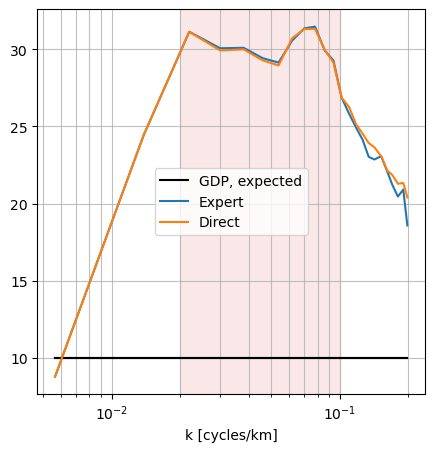

In [51]:
fig,ax = plt.subplots(figsize=(5,5))

if True:
    ax.plot(curve_nohret.kc,100*curve_nohret['expected'],c='k')
    ax.plot(curve_nohret.kc,100*curve_nohret_direct['expected'],c='k',label='GDP, expected')
    ax.plot(curve_nohret.kc,100*curve_nohret['expected']*curve_nohret.lift,label='Expert')
    ax.plot(curve_nohret_direct.kc,100*curve_nohret_direct['expected']*curve_nohret_direct.lift,label='Direct')
#ax.plot(curve_nohret.kc,curve_nohret.lift)
#ax.plot(curve_nohret_direct.kc,curve_nohret_direct.lift)
ax.axvspan(1/50, 1/10, color='C3', alpha=.1); ax.set_xscale('log'); ax.set_xlabel('k [cycles/km]')
ax.grid(which='both',alpha=0.8);ax.legend()